# Assignment 1 — HSBC Customer Segmentation and Marketing

## Research question: Which existing HSBC customers aged 18–34 should be prioritised for a digital-channel credit-card promotion trial that generates new cards and sustained use?
This study focuses on deepening existing customer relationships. Credit cards support everyday payments, and the data identify both digital-banking registration and HSBC card ownership. The analysis therefore connects candidate size, customer differences and trial design. Python-based cleaning retains 47,882 records, including 18,294 digitally registered non-cardholders. A five-variable K-prototypes model selects seven segments, with the highest tested silhouette score of 0.5087; hierarchical clustering adds evidence on financial and channel differences. 
G4 and G5 are recommended as the first trial strata. Their 8,949 candidates represent 48.9% of the pool and can receive the same everyday-payment proposition. Coverage, existing relationships and implementation feasibility motivate this choice; incremental sustained card use in a randomised trial should determine expansion.


### 0 Settings


In [6]:
from pathlib import Path
import json
import time
import platform
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, pairwise_distances
from sklearn.model_selection import StratifiedKFold
from scipy.optimize import linear_sum_assignment
import joblib

BASE_DIR = Path.cwd()
DATA_PATH = BASE_DIR / 'Assignment 1 data file - HSBC .xlsx'
OUTPUT_DIR = Path.cwd() / 'outputs'
TABLE_DIR = OUTPUT_DIR / 'tables'
FIGURE_DIR = OUTPUT_DIR / 'figures'
MODEL_DIR = OUTPUT_DIR / 'models'
for folder in [TABLE_DIR, FIGURE_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 20261102
K_VALUES = list(range(2, 13))
N_INIT = 50 # 每种 K 用 50 组初始中心重复运行 K-means。
MAX_ITER = 300
SILHOUETTE_N = 5000 # 如果后续用轮廓系数评估 K，最多抽 5,000 条来算这个指标。
FINAL_K_OVERRIDE = None
FINAL_K_REASON = ''  # 人工选择时填写；不预设七群或五群。
N_STABILITY_RUNS = 10
HIERARCHY_NEIGHBORS = 30

ORIGINAL_COLS = ['AGE', 'INCOME', 'TRB', 'DIG_ACTIVE', 'FX_TRANS', 'PAYME',
                 'CC', 'LN', 'MT', 'TD', 'SC', 'SP', 'BD', 'MPF']
MONEY_COLS = ['INCOME', 'TRB']
DIGITAL_COLS = ['DIG_ACTIVE', 'PAYME', 'FX_TRANS']
PRODUCT_COLS = ['CC', 'LN', 'MT', 'TD', 'SC', 'SP', 'BD', 'MPF']
BINARY_COLS = [c for c in ORIGINAL_COLS if c not in ['AGE', *MONEY_COLS]]
FEATURE_COLS = MONEY_COLS + DIGITAL_COLS
AGE_ORDER = ['18-24', '25-29', '30-34']

MORANDI_PALETTE = [
    "#8299A3",  # 灰蓝
    "#B8877C",  # 灰粉
    "#9AA58B",  # 豆绿
    "#9B8FA5",  # 藕紫
    "#C5A77D",  # 沙色
    "#78968C",  # 灰绿
    "#B69C9A",  # 灰玫瑰
    "#7D8998",  # 雾霾蓝
    "#C49A83",  # 陶土色
    "#A5A18B",  # 灰橄榄
    "#A8879A",  # 灰紫红
    "#8FA49A",  # 鼠尾草绿
]

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font="DejaVu Sans",
    palette=MORANDI_PALETTE
)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#D5D1CC",
    "grid.color": "#E7E3DE",
    "grid.linewidth": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

BLUE = "#8299A3"
RED = "#B8877C"

LABELS = {
    "DIG_ACTIVE": "Digital banking",
    "PAYME": "PayMe",
    "FX_TRANS": "FX transaction",
    "CC": "Credit card",
    "LN": "Personal loan",
    "MT": "Mortgage",
    "TD": "Term deposit",
    "SC": "Securities",
    "SP": "Structured products",
    "BD": "Bonds",
    "MPF": "MPF"
}

def segment_palette(k):
    return MORANDI_PALETTE[:k]

def save_figure(fig, name):
    fig.tight_layout()
    for extension in ['png', 'pdf']:
        fig.savefig(FIGURE_DIR / f'{name}.{extension}', bbox_inches='tight')
    plt.show()
    plt.close(fig)

def export_tables(filename, sheets):
    # 用户已要求 Excel 导出；数值保留原始精度，只设置显示格式。
    with pd.ExcelWriter(TABLE_DIR / filename, engine='openpyxl') as writer:
        for sheet, frame in sheets.items():
            frame.to_excel(writer, sheet_name=sheet[:31], index=True)
            ws = writer.sheets[sheet[:31]]
            ws.freeze_panes = 'B2'
            ws.auto_filter.ref = ws.dimensions
            for row in ws.iter_rows(min_row=2):
                for cell in row:
                    if isinstance(cell.value, float):
                        cell.number_format = '#,##0.000'
            for column in ws.columns:
                width = min(32, max(12, max(len(str(c.value or '')) for c in list(column)[:30]) + 2))
                ws.column_dimensions[column[0].column_letter].width = width

environment = pd.DataFrame({'Version': {name: version(name) for name in
    ['pandas', 'numpy', 'scikit-learn', 'scipy', 'matplotlib', 'seaborn', 'openpyxl']}})
environment.loc['Python', 'Version'] = platform.python_version()
display(environment)
print('Data file exists:', DATA_PATH.exists())
print('Outputs:', OUTPUT_DIR)


,Version
pandas,2.2.3
numpy,2.1.3
scikit-learn,1.6.1
scipy,1.15.3
matplotlib,3.10.3
seaborn,0.13.2
openpyxl,3.1.5
Python,3.11.8


Data file exists: True
Outputs: /Users/cby/Documents/Codex/2026-10-31/gei-w/outputs


## Q1. Data Cleaning — Technical Data Cleaning (15 points)

### 1.1 Load the New Dataset and Preserve Source Row Numbers

Load the new Excel file. Preserve each record’s original Excel row number (the header is in row 1, so the first data record is in row 2) to make it possible to trace records back to the source file.

In [7]:
excel_file = pd.ExcelFile(DATA_PATH)
print('Worksheets:', excel_file.sheet_names)
df_raw = pd.read_excel(DATA_PATH, sheet_name='Synthetic Data')
if df_raw.columns.tolist() != ORIGINAL_COLS:
    raise ValueError(f'Unexpected columns: {df_raw.columns.tolist()}')
df_raw.index = pd.Index(np.arange(2, len(df_raw) + 2), name='Source_Row')
print('Raw data shape:', df_raw.shape)
display(df_raw.head())
display(pd.DataFrame({'Dtype': df_raw.dtypes.astype(str),
                      'Missing_Cells': df_raw.isna().sum()}))


Worksheets: ['Synthetic Data']
Raw data shape: (50000, 14)


,AGE,INCOME,TRB,DIG_ACTIVE,FX_TRANS,PAYME,CC,LN,MT,TD,SC,SP,BD,MPF
Source_Row,,,,,,,,,,,,,,
2,30-34,9012.126323,62051.474999,0,0,1,0,0,0,0,0,0,0,1
3,30-34,44108.030639,4.053788,1,0,0,1,0,0,0,0,0,0,0
4,25-29,45782.412638,291995.998395,1,0,0,0,0,0,0,0,0,0,0
5,30-34,26525.406385,81.503869,1,0,0,0,0,0,0,1,0,0,0
6,30-34,20671.511249,1447.011647,1,0,1,0,0,0,0,0,0,0,0


,Dtype,Missing_Cells
AGE,object,0
INCOME,object,0
TRB,float64,0
DIG_ACTIVE,int64,0
FX_TRANS,int64,0
PAYME,object,0
CC,int64,0
LN,int64,0
MT,int64,0
TD,int64,0



### 1.2 Check Field Formats and Suspicious Values

Check data quality against the expected field types: age should match one of the three age bands, monetary fields should be numeric, and digital service and product fields should be coded as 0 or 1. Check for missing values, unparseable entries, non-finite numbers, and values outside the expected range.

In [8]:
df_parsed = df_raw.copy()
audit = pd.DataFrame(index=df_raw.index)

# Check that age values match the expected age bands
audit["AGE_INVALID_FLAG"] = (
    ~df_raw["AGE"].astype("string").str.strip().isin(AGE_ORDER)
)

# Check whether monetary and binary fields can be parsed as numbers
for col in MONEY_COLS + BINARY_COLS:
    parsed = pd.to_numeric(df_raw[col], errors="coerce")
    df_parsed[col] = parsed

    # Non-missing source values that cannot be parsed as numbers
    audit[f"{col}_PARSE_ERROR_FLAG"] = (
        df_raw[col].notna() & parsed.isna()
    )

    # Non-finite numeric values, such as positive or negative infinity
    audit[f"{col}_NONFINITE_FLAG"] = (
        parsed.notna() & ~np.isfinite(parsed)
    )

# Binary fields are expected to contain only 0 or 1
for col in BINARY_COLS:
    parsed = df_parsed[col]
    finite_values = parsed.notna() & np.isfinite(parsed)

    audit[f"{col}_NOT_0_OR_1_FLAG"] = (
        finite_values & ~parsed.isin([0, 1])
    )

# Summarize technical issues only
technical_issue_cols = list(audit.columns)
audit["TECHNICAL_FLAG"] = audit[technical_issue_cols].any(axis=1)

q1_summary = (
    audit[technical_issue_cols]
    .sum()
    .loc[lambda counts: counts > 0]
    .rename("Flagged_Records")
    .to_frame()
)

print("Missing cells in raw data:", int(df_raw.isna().sum().sum()))
print("Records with technical issues:", int(audit["TECHNICAL_FLAG"].sum()))

print("\nTechnical issues by check:")
display(q1_summary)

technical_rows = audit["TECHNICAL_FLAG"]
technical_flag_cols = [
    col for col in technical_issue_cols
    if audit.loc[technical_rows, col].any()
]

technical_details = pd.concat(
    [
        df_raw.loc[technical_rows],
        audit.loc[technical_rows, technical_flag_cols]
    ],
    axis=1
)

print("\nOriginal records with technical issues:")
display(technical_details)

Missing cells in raw data: 0
Records with technical issues: 3

Technical issues by check:


,Flagged_Records
INCOME_PARSE_ERROR_FLAG,1
PAYME_PARSE_ERROR_FLAG,1
MPF_NOT_0_OR_1_FLAG,1



Original records with technical issues:


,AGE,INCOME,TRB,DIG_ACTIVE,FX_TRANS,PAYME,CC,LN,MT,TD,SC,SP,BD,MPF,INCOME_PARSE_ERROR_FLAG,PAYME_PARSE_ERROR_FLAG,MPF_NOT_0_OR_1_FLAG
Source_Row,,,,,,,,,,,,,,,,,
39721,25-29,ABCDEFG,11380.011308,1,0,1,0,0,0,0,0,0,0,0,True,False,False
43533,25-29,20642.826295,113136.260995,1,0,X,1,0,0,0,0,0,0,1,False,True,False
45206,25-29,25300.414447,233250.307803,1,1,1,1,0,0,0,0,0,1,-1,False,False,True


原始数据共 50,000 条记录，没有缺失单元格。检查发现 3 条记录存在技术性问题：INCOME 中有一个无法解析的文本值（ABCDEFG），PAYME 中有一个非数值字符（X），MPF 中有一个不符合 0/1 编码的值（-1）。


The raw dataset contains 50,000 records and no missing cells. Three records have technical data issues: one unparseable text value (ABCDEFG) in INCOME, one non-numeric value (X) in PAYME, and one value (-1) in MPF that falls outside the expected 0/1 coding. 

### 1.3 Create the Q1 Analysis Sample and Record Exclusion Reasons

The Q1 checks identified three records with technical data issues. To prevent unparseable values or values that violate the field coding from affecting subsequent analyses, exclude these three records from the Q1 analysis sample. Preserve the original records, source row numbers, and reasons for exclusion in the audit output. Do not overwrite or modify the raw dataset.

Negative income is numeric and parseable, so it is not excluded at this stage. It will be examined as a suspicious value in Question 3. Duplicate records and other systematic data issues will also be examined in Question 3.

In [9]:
technical_rows = audit["TECHNICAL_FLAG"]

audit["Q1_Reason"] = audit[technical_issue_cols].apply(
    lambda row: "; ".join(row.index[row.astype(bool)]),
    axis=1
)

df_q1 = df_parsed.loc[~technical_rows].copy()
df_q1[BINARY_COLS] = df_q1[BINARY_COLS].astype(int)

q1_flow = pd.DataFrame({
    "Records": {
        "Raw records": len(df_raw),
        "Excluded for technical issues": int(technical_rows.sum()),
        "Retained after Q1": len(df_q1)
    }
})

print("Q1 analysis sample shape:", df_q1.shape)
print("Technical records excluded:", int(technical_rows.sum()))
print("Negative-income records retained for Q3:", int((df_q1["INCOME"] < 0).sum()))

print("\nQ1 sample flow:")
display(q1_flow)

technical_error_rows = df_raw.join(audit).loc[technical_rows]

export_tables(
    "Q1_technical_audit.xlsx",
    {
        "Rule Counts": q1_summary,
        "Sample Flow": q1_flow,
        "Technical Error Rows": technical_error_rows
    }
)

Q1 analysis sample shape: (49997, 14)
Technical records excluded: 3
Negative-income records retained for Q3: 665

Q1 sample flow:


,Records
Raw records,50000
Excluded for technical issues,3
Retained after Q1,49997


## Q2. Data Description (10 points)

### 2.1 Describe the Q1 Sample

This section describes the sample retained after the technical checks in Question 1. It reports the sample size and missing values, followed by descriptive statistics for monetary fields, the age-band distribution, and the 0/1 distributions of digital service and product fields.

Records with negative income remain in these descriptive statistics. Their plausibility will be examined as suspicious values in Question 3.

In [10]:
summary_rows = []

# Monetary variables
for col in MONEY_COLS:
    values = df_q1[col].dropna()

    summary_rows.append({
        "Variable": col,
        "Variable_Type": "Monetary",
        "Count": values.count(),
        "Missing": int(df_q1[col].isna().sum()),
        "Mean": values.mean(),
        "Std": values.std(),
        "Min": values.min(),
        "P25": values.quantile(0.25),
        "Median": values.median(),
        "P75": values.quantile(0.75),
        "Max": values.max()
    })

# Binary variables
for col in BINARY_COLS:
    values = df_q1[col].dropna().astype(int)
    counts = values.value_counts()

    summary_rows.append({
        "Variable": col,
        "Variable_Type": "Binary",
        "Count": values.count(),
        "Missing": int(df_q1[col].isna().sum()),
        "Mean": values.mean(),
        "Std": values.std(),
        "Min": values.min(),
        "P25": values.quantile(0.25),
        "Median": values.median(),
        "P75": values.quantile(0.75),
        "Max": values.max(),
        "Count_0": int(counts.get(0, 0)),
        "Count_1": int(counts.get(1, 0)),
        "Share_1_Percent": values.mean() * 100
    })

# Age-band variable
age_counts = df_q1["AGE"].value_counts().reindex(AGE_ORDER, fill_value=0)
age_mode = age_counts.idxmax()

summary_rows.append({
    "Variable": "AGE",
    "Variable_Type": "Categorical",
    "Count": int(age_counts.sum()),
    "Missing": int(df_q1["AGE"].isna().sum()),
    "Mode": age_mode,
    "Mode_Frequency": int(age_counts.max()),
    "Mode_Percent": age_counts.max() / len(df_q1) * 100,
    "Distribution": "; ".join(
        f"{age}: {age_counts[age] / len(df_q1) * 100:.2f}%"
        for age in AGE_ORDER
    )
})

descriptive_summary = (
    pd.DataFrame(summary_rows)
    .set_index("Variable")
)

display(descriptive_summary.round(3))

export_tables(
    "Q2_descriptive_statistics.xlsx",
    {"Descriptive Statistics": descriptive_summary}
)

print("Exported: ", TABLE_DIR / "Q2_descriptive_statistics.xlsx")

,Variable_Type,Count,Missing,Mean,Std,Min,P25,Median,P75,Max,Count_0,Count_1,Share_1_Percent,Mode,Mode_Frequency,Mode_Percent,Distribution
Variable,,,,,,,,,,,,,,,,,
INCOME,Monetary,49997,0,31230.326,25893.376,-19669.875,18554.494,27108.255,39868.497,1.380715e+06,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TRB,Monetary,49997,0,162784.410,391718.759,0.000,4680.324,37898.331,170340.024,2.282008e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DIG_ACTIVE,Binary,49997,0,0.818,0.386,0.000,1.000,1.000,1.000,1.000000e+00,9093.0,40904.0,81.813,NaN,NaN,NaN,NaN
FX_TRANS,Binary,49997,0,0.237,0.425,0.000,0.000,0.000,0.000,1.000000e+00,38130.0,11867.0,23.735,NaN,NaN,NaN,NaN
PAYME,Binary,49997,0,0.666,0.472,0.000,0.000,1.000,1.000,1.000000e+00,16716.0,33281.0,66.566,NaN,NaN,NaN,NaN
CC,Binary,49997,0,0.488,0.500,0.000,0.000,0.000,1.000,1.000000e+00,25581.0,24416.0,48.835,NaN,NaN,NaN,NaN
LN,Binary,49997,0,0.076,0.266,0.000,0.000,0.000,0.000,1.000000e+00,46176.0,3821.0,7.642,NaN,NaN,NaN,NaN
MT,Binary,49997,0,0.078,0.267,0.000,0.000,0.000,0.000,1.000000e+00,46121.0,3876.0,7.752,NaN,NaN,NaN,NaN
TD,Binary,49997,0,0.093,0.291,0.000,0.000,0.000,0.000,1.000000e+00,45337.0,4660.0,9.321,NaN,NaN,NaN,NaN


Exported:  /Users/cby/Documents/Codex/2026-10-31/gei-w/outputs/tables/Q2_descriptive_statistics.xlsx


## Q3. Data Problems and Potential Biases (10 points)

### 3.1 Problem Categories and Checks

| Problem category | Rule | Check | Treatment |
|---|---|---|---|
| Odd values | R1 | Monthly income below 0 | Flag and examine the count and distribution; do not replace with 0 |
| Potential inconsistencies | R2 | TRB = 0 and at least one balance-related product indicator equals 1 | Summarize as one issue category and report its three subcases; do not automatically alter the original values |
| Duplicates | R3 | Extra records identical across all 14 original fields, including AGE, INCOME, TRB, and all binary fields | Keep the first occurrence in each group and exclude subsequent exact matches |

> **Note — R1:** Negative income is numeric and parseable, so it is not a format error. Examine and report its count and distribution as a suspicious value; do not replace it with zero.

> **Note — R2:** This rule summarizes records with TRB = 0 and at least one balance-related product indicator. It has three subcases:  
> (a) TD = 1;  
> (b) at least one of SC, SP, or BD equals 1;  
> (c) at least one of LN or MT equals 1.  
> The subcases may overlap, so the total R2 count is the union of distinct records. Flag these records; do not automatically change TRB or product indicators.

> **Note — R3:** Flag a record as a duplicate only when all 14 original fields match exactly. Records with TRB = 0 and matching binary fields, but different INCOME or other fields, are not treated as duplicates. Keep the first occurrence in each group, and record excluded rows and source row numbers in the exclusion log.


### R1

In [11]:
r1_mask = df_q1["INCOME"] < 0

audit["R1_INCOME_NEGATIVE_FLAG"] = False
audit.loc[df_q1.index, "R1_INCOME_NEGATIVE_FLAG"] = r1_mask

negative_income_summary = (
    df_q1.loc[r1_mask, "INCOME"]
    .describe(percentiles=[0.25, 0.50, 0.75])
    .rename("INCOME")
    .to_frame()
)

print("Negative-income records:", int(r1_mask.sum()))
print("Share of Q1 sample (%):", round(r1_mask.mean() * 100, 2))

print("\nNegative-income distribution:")
display(negative_income_summary)

print("\nTen lowest-income records:")
display(
    df_q1.loc[r1_mask, ["AGE", "INCOME", "TRB"]]
    .nsmallest(10, "INCOME")
)

Negative-income records: 665
Share of Q1 sample (%): 1.33

Negative-income distribution:


,INCOME
count,665.000000
mean,-6110.637940
std,3600.851706
min,-19669.875444
25%,-9431.520100
50%,-5468.740262
75%,-3584.090156
max,-42.380801



Ten lowest-income records:


,AGE,INCOME,TRB
Source_Row,,,
25776,25-29,-19669.875444,65289.178737
33876,30-34,-16972.648498,14002.881444
32256,30-34,-16518.664067,21178.233991
11462,25-29,-14366.782138,55199.869485
4996,18-24,-14262.644937,37309.835346
24558,30-34,-14199.906833,171658.039212
2142,30-34,-12096.391785,87442.957186
4365,18-24,-12059.035257,0.000000
23551,25-29,-12059.035257,0.000000


### R2

In [12]:
q3_flags = pd.DataFrame(index=df_q1.index)
q3_flags["R1_INCOME_NEGATIVE_FLAG"] = (
    audit.loc[df_q1.index, "R1_INCOME_NEGATIVE_FLAG"].astype(bool)
)

r2_flags = pd.DataFrame(index=df_q1.index)

r2_flags["R2A_TRB_ZERO_TD_FLAG"] = (
    df_q1["TRB"].eq(0) & df_q1["TD"].eq(1)
)

r2_flags["R2B_TRB_ZERO_INVESTMENT_FLAG"] = (
    df_q1["TRB"].eq(0)
    & df_q1[["SC", "SP", "BD"]].eq(1).any(axis=1)
)

r2_flags["R2C_TRB_ZERO_LOAN_FLAG"] = (
    df_q1["TRB"].eq(0)
    & df_q1[["LN", "MT"]].eq(1).any(axis=1)
)

r2_flags["R2_TRB_ZERO_PRODUCT_FLAG"] = r2_flags.any(axis=1)

q3_flags = q3_flags.join(r2_flags)

# Store the flags in the audit table without removing any records
for col in r2_flags.columns:
    audit[col] = False
    audit.loc[df_q1.index, col] = r2_flags[col]

r2_counts = r2_flags.sum().rename("Flagged_Records").to_frame()

print("R2 subcase counts and overall distinct count:")
display(r2_counts)

print(
    "R2 records flagged by at least one subcase:",
    int(r2_flags["R2_TRB_ZERO_PRODUCT_FLAG"].sum())
)

print("\nExamples of R2 records:")
display(
    df_q1.loc[
        r2_flags["R2_TRB_ZERO_PRODUCT_FLAG"],
        ["AGE", "INCOME", "TRB", "TD", "SC", "SP", "BD", "LN", "MT"]
    ].head(10)
)

R2 subcase counts and overall distinct count:


,Flagged_Records
R2A_TRB_ZERO_TD_FLAG,79
R2B_TRB_ZERO_INVESTMENT_FLAG,226
R2C_TRB_ZERO_LOAN_FLAG,182
R2_TRB_ZERO_PRODUCT_FLAG,435


R2 records flagged by at least one subcase: 435

Examples of R2 records:


,AGE,INCOME,TRB,TD,SC,SP,BD,LN,MT
Source_Row,,,,,,,,,
89,30-34,20636.586419,0.0,0,0,1,0,0,0
106,25-29,30583.962899,0.0,1,0,0,0,0,0
133,18-24,38223.176793,0.0,0,0,0,1,0,0
331,30-34,27084.951825,0.0,0,0,1,0,0,0
609,30-34,38171.984421,0.0,0,1,0,0,0,0
775,30-34,20636.586419,0.0,0,1,0,0,0,0
994,30-34,26521.176802,0.0,0,0,0,1,0,0
1185,30-34,26521.176802,0.0,1,0,0,0,0,0
1352,30-34,38223.176793,0.0,1,0,0,0,0,0


### R3

In [13]:
duplicate_mask = df_q1.duplicated(
    subset=ORIGINAL_COLS,
    keep="first"
)

duplicate_group_mask = df_q1.duplicated(
    subset=ORIGINAL_COLS,
    keep=False
)

duplicate_groups = (
    df_q1.loc[duplicate_group_mask, ORIGINAL_COLS]
    .drop_duplicates()
)

q3_flags["R3_EXACT_DUPLICATE_FLAG"] = duplicate_mask

audit["R3_EXACT_DUPLICATE_FLAG"] = False
audit.loc[df_q1.index, "R3_EXACT_DUPLICATE_FLAG"] = duplicate_mask

print("Extra exact duplicate records:", int(duplicate_mask.sum()))
print("Records belonging to exact-duplicate groups:", int(duplicate_group_mask.sum()))
print("Number of exact-duplicate groups:", len(duplicate_groups))

print("\nExamples of extra duplicate records:")
display(df_q1.loc[duplicate_mask, ORIGINAL_COLS].head(10))

Extra exact duplicate records: 1195
Records belonging to exact-duplicate groups: 1350
Number of exact-duplicate groups: 155

Examples of extra duplicate records:


,AGE,INCOME,TRB,DIG_ACTIVE,FX_TRANS,PAYME,CC,LN,MT,TD,SC,SP,BD,MPF
Source_Row,,,,,,,,,,,,,,
1105,30-34,38223.176793,0.0,1,0,1,1,0,0,0,0,0,0,0
1178,25-29,20636.586419,0.0,1,0,1,0,0,0,0,0,0,0,0
1196,30-34,38223.176793,0.0,1,0,1,1,0,0,0,0,0,0,0
1309,30-34,38223.176793,0.0,1,0,1,1,0,0,0,0,0,0,0
1647,30-34,20636.586419,0.0,1,0,1,0,0,0,0,0,1,0,0
1661,30-34,20636.586419,0.0,1,0,1,0,0,0,0,0,0,0,0
2058,25-29,38223.176793,0.0,1,0,1,1,0,0,0,0,0,0,0
2098,25-29,20636.586419,0.0,1,0,1,0,0,0,0,0,0,0,0
2273,30-34,26521.176802,0.0,1,0,0,0,0,0,0,0,0,0,0


In [14]:
q3_exclusion_mask = q3_flags["ANY_Q3_FLAG"]

df_analysis = df_q1.loc[~q3_exclusion_mask].copy()

df_q3_excluded = (
    df_q1.loc[q3_exclusion_mask]
    .join(q3_flags.loc[q3_exclusion_mask])
)

sample_flow = pd.DataFrame({
    "Records": {
        "Raw records": len(df_raw),
        "Excluded for Q1 technical issues": int(audit["TECHNICAL_FLAG"].sum()),
        "Q1 sample records": len(df_q1),
        "Excluded by at least one Q3 rule": int(q3_exclusion_mask.sum()),
        "Final analysis records": len(df_analysis)
    }
})

print("Final analysis sample shape:", df_analysis.shape)
print("Q3 excluded records:", len(df_q3_excluded))

print("\nSample flow:")
display(sample_flow)

print("\nExcluded records by matched Q3 rule pattern:")
display(
    df_q3_excluded["RULE_PATTERN"]
    .value_counts()
    .rename_axis("Rule_Pattern")
    .to_frame("Records")
)

Final analysis sample shape: (47882, 14)
Q3 excluded records: 2115

Sample flow:


,Records
Raw records,50000
Excluded for Q1 technical issues,3
Q1 sample records,49997
Excluded by at least one Q3 rule,2115
Final analysis records,47882



Excluded records by matched Q3 rule pattern:


,Records
Rule_Pattern,
R3,1016
R1,664
R2,255
R2 + R3,179
R1 + R2,1


In [15]:
# Remove records flagged by any Q3 rule and export the retained and excluded records.
# Exclude negative income and exact duplicates.
# Retain records flagged only for R2 product/balance inconsistencies.
# Restore the original exclusion rules: R1, R2, and R3.
q3_exclusion_mask = (
    q3_flags["R1_INCOME_NEGATIVE_FLAG"]
    | q3_flags["R2_TRB_ZERO_PRODUCT_FLAG"]
    | q3_flags["R3_EXACT_DUPLICATE_FLAG"]
)

df_analysis = df_q1.loc[~q3_exclusion_mask].copy()
df_q3_excluded = df_q1.loc[q3_exclusion_mask].join(
    q3_flags.loc[q3_exclusion_mask]
)

output_path = TABLE_DIR / "HSBC_Q3_cleaned.xlsx"

with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
    df_analysis.to_excel(writer, sheet_name="Analysis Data", index=True)
    df_q3_excluded.to_excel(writer, sheet_name="Q3 Excluded", index=True)

print("Q1 sample records:", len(df_q1))
print("Q3 excluded records:", len(df_q3_excluded))
print("Final analysis records:", len(df_analysis))
print("Exported to:", output_path)

Q1 sample records: 49997
Q3 excluded records: 2115
Final analysis records: 47882
Exported to: /Users/cby/Documents/Codex/2026-10-31/gei-w/outputs/tables/HSBC_Q3_cleaned.xlsx


This question first applies K-means to divide customers into 10 clusters. The first model uses only the continuous variables `INCOME` and `TRB` to examine how customers group by income and total relationship balance. Both variables are right-skewed, so they are transformed using `log(1+x)` and then standardized to reduce the influence of extreme amounts on distance calculations.

After clustering, report the number of customers in each cluster and the mean `INCOME` and `TRB`. Use age, digital-service, and product-holding profiles to interpret the business characteristics of each cluster. A K-prototypes model using both continuous and binary variables will then be used for comparison. Both methods use 10 clusters; the choice of the best number of clusters is addressed in Q5.

PCA projects the clustering variables into two dimensions for visualization. The plot is useful for viewing the cluster structure, but it cannot show all differences in the original variables.

In [16]:
from sklearn.preprocessing import StandardScaler

q4_continuous_cols = ["INCOME", "TRB"]

q4_continuous = df_analysis[q4_continuous_cols].copy()

if q4_continuous.isna().any().any():
    raise ValueError("Missing values found in the Q4 clustering variables.")

if (q4_continuous < 0).any().any():
    raise ValueError(
        "Negative values found. Check that the Q3 exclusions were applied."
    )

q4_log = np.log1p(q4_continuous)

q4_scaler = StandardScaler()
X_q4_kmeans = q4_scaler.fit_transform(q4_log)

print("Q4 sample size:", len(df_analysis))
print("Variables used:", q4_continuous_cols)
print("Prepared data shape:", X_q4_kmeans.shape)
print("Missing values after preparation:", int(np.isnan(X_q4_kmeans).sum()))

Q4 sample size: 47882
Variables used: ['INCOME', 'TRB']
Prepared data shape: (47882, 2)
Missing values after preparation: 0


### 4.2 K=10 Cluster Profiles and Means on the Original Scale

The solution with the lowest inertia is retained from 50 initializations, using a fixed random seed. For each K, clusters are numbered in ascending order of median income. The same cluster number across different values of K does not imply the same set of customers.

The profile table reports means on the original scale to meet the Q4 requirements, alongside medians to describe typical customers in right-skewed distributions. Binary variables are reported as percentages.

After running the analysis, interpret the results in terms of customer characteristics and business implications: What financial profiles emerge from the combinations of income and TRB? How does the proportion of customers with digital banking enabled but no credit card differ across clusters? Which clusters could share a marketing trial, and which should be evaluated separately? The numerical profiles provide evidence for these interpretations but cannot replace business judgment.

In [17]:
from sklearn.preprocessing import StandardScaler

q4_continuous_cols = ["INCOME", "TRB"]

q4_continuous = df_analysis[q4_continuous_cols].copy()

if q4_continuous.isna().any().any():
    raise ValueError("Missing values found in the Q4 clustering variables.")

if (q4_continuous < 0).any().any():
    raise ValueError(
        "Negative values found. Check that the Q3 exclusions were applied."
    )

q4_log = np.log1p(q4_continuous)

q4_scaler = StandardScaler()
X_q4_kmeans = q4_scaler.fit_transform(q4_log)

print("Q4 sample size:", len(df_analysis))
print("Variables used:", q4_continuous_cols)
print("Prepared data shape:", X_q4_kmeans.shape)
print("Missing values after preparation:", int(np.isnan(X_q4_kmeans).sum()))

Q4 sample size: 47882
Variables used: ['INCOME', 'TRB']
Prepared data shape: (47882, 2)
Missing values after preparation: 0


### Kmeans when K = 10

In [18]:
q4_kmeans = KMeans(
    n_clusters=10,
    n_init=50,
    max_iter=300,
    random_state=RANDOM_STATE
)

df_analysis["KMEANS_K10"] = q4_kmeans.fit_predict(X_q4_kmeans)

q4_cluster_summary = (
    df_analysis
    .groupby("KMEANS_K10")
    .agg(
        Customers=("KMEANS_K10", "size"),
        Average_Income_HKD=("INCOME", "mean"),
        Average_TRB_HKD=("TRB", "mean")
    )
)

q4_cluster_summary["Share_Percent"] = (
    q4_cluster_summary["Customers"] / len(df_analysis) * 100
)

q4_cluster_summary = q4_cluster_summary[
    ["Customers", "Share_Percent", "Average_Income_HKD", "Average_TRB_HKD"]
].sort_index()

print("K-means clusters: 10")
print("K-means inertia:", round(q4_kmeans.inertia_, 3))
display(q4_cluster_summary.round(3))

K-means clusters: 10
K-means inertia: 12455.63


,Customers,Share_Percent,Average_Income_HKD,Average_TRB_HKD
KMEANS_K10,,,,
0,9758,20.379,43367.265,217769.893
1,5019,10.482,28373.699,997.110
2,5077,10.603,11584.412,63898.289
3,1944,4.060,4687.030,47241.086
4,2012,4.202,8322.331,763.751
5,9908,20.693,31379.943,14612.461
6,1659,3.465,25530.876,20.494
7,7845,16.384,24005.747,219316.654
8,406,0.848,789.264,87161.169


In [19]:
q4_profile_cols = [col for col in BINARY_COLS if col in df_analysis.columns]

q4_binary_profile = (
    df_analysis
    .groupby("KMEANS_K10")[q4_profile_cols]
    .mean()
    .mul(100)
    .rename(columns=lambda col: f"{col}_Percent")
)

q4_age_profile = (
    pd.crosstab(
        df_analysis["KMEANS_K10"],
        df_analysis["AGE"],
        normalize="index"
    )
    .mul(100)
    .rename(columns=lambda age: f"AGE_{age}_Percent")
)

q4_financial_profile = (
    df_analysis
    .groupby("KMEANS_K10")
    .agg(
        Customers=("KMEANS_K10", "size"),
        Mean_Income_HKD=("INCOME", "mean"),
        Median_Income_HKD=("INCOME", "median"),
        Mean_TRB_HKD=("TRB", "mean"),
        Median_TRB_HKD=("TRB", "median")
    )
)

q4_full_profile = (
    q4_financial_profile
    .join(q4_age_profile)
    .join(q4_binary_profile)
)

display(q4_full_profile.round(2))

,Customers,Mean_Income_HKD,Median_Income_HKD,Mean_TRB_HKD,Median_TRB_HKD,AGE_18-24_Percent,AGE_25-29_Percent,AGE_30-34_Percent,DIG_ACTIVE_Percent,FX_TRANS_Percent,PAYME_Percent,CC_Percent,LN_Percent,MT_Percent,TD_Percent,SC_Percent,SP_Percent,BD_Percent,MPF_Percent
KMEANS_K10,,,,,,,,,,,,,,,,,,,
0,9758,43367.26,42471.41,217769.89,159135.90,19.67,34.78,45.55,92.10,34.41,74.48,74.16,9.96,10.04,11.02,11.54,4.95,9.14,33.17
1,5019,28373.70,26549.98,997.11,786.78,41.14,30.19,28.67,89.60,18.91,60.77,35.33,4.94,5.72,5.24,4.54,5.22,4.78,8.37
2,5077,11584.41,11179.48,63898.29,36004.26,33.64,32.26,34.09,65.14,17.69,55.13,27.30,6.70,5.79,8.82,9.75,4.83,6.48,40.71
3,1944,4687.03,5050.26,47241.09,15089.66,50.46,26.80,22.74,74.79,14.76,80.35,23.15,6.02,6.43,7.36,8.18,5.04,4.78,48.41
4,2012,8322.33,9506.52,763.75,472.53,34.54,29.92,35.54,23.86,8.40,31.81,8.05,4.82,4.08,5.67,5.02,4.87,5.47,13.17
5,9908,31379.94,29037.21,14612.46,11933.74,38.33,30.64,31.03,91.09,23.73,68.21,51.62,5.92,6.08,5.42,5.69,5.14,4.99,14.85
6,1659,25530.88,26393.26,20.49,11.63,33.76,34.60,31.65,74.86,17.78,53.47,32.01,4.76,4.70,4.88,5.24,3.38,4.28,5.97
7,7845,24005.75,24531.57,219316.65,135804.04,20.71,36.62,42.66,86.59,21.77,75.05,51.29,10.11,7.85,13.55,13.42,5.10,8.83,47.32
8,406,789.26,804.46,87161.17,37172.60,52.46,25.86,21.67,78.57,22.66,69.95,34.73,7.64,5.17,13.30,12.81,4.43,9.85,35.96


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/var/folders/h_/blbk02vs6dx5_ydq21qlv4qm0000gn/T/ipykernel_14022/3784107419.py:33: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


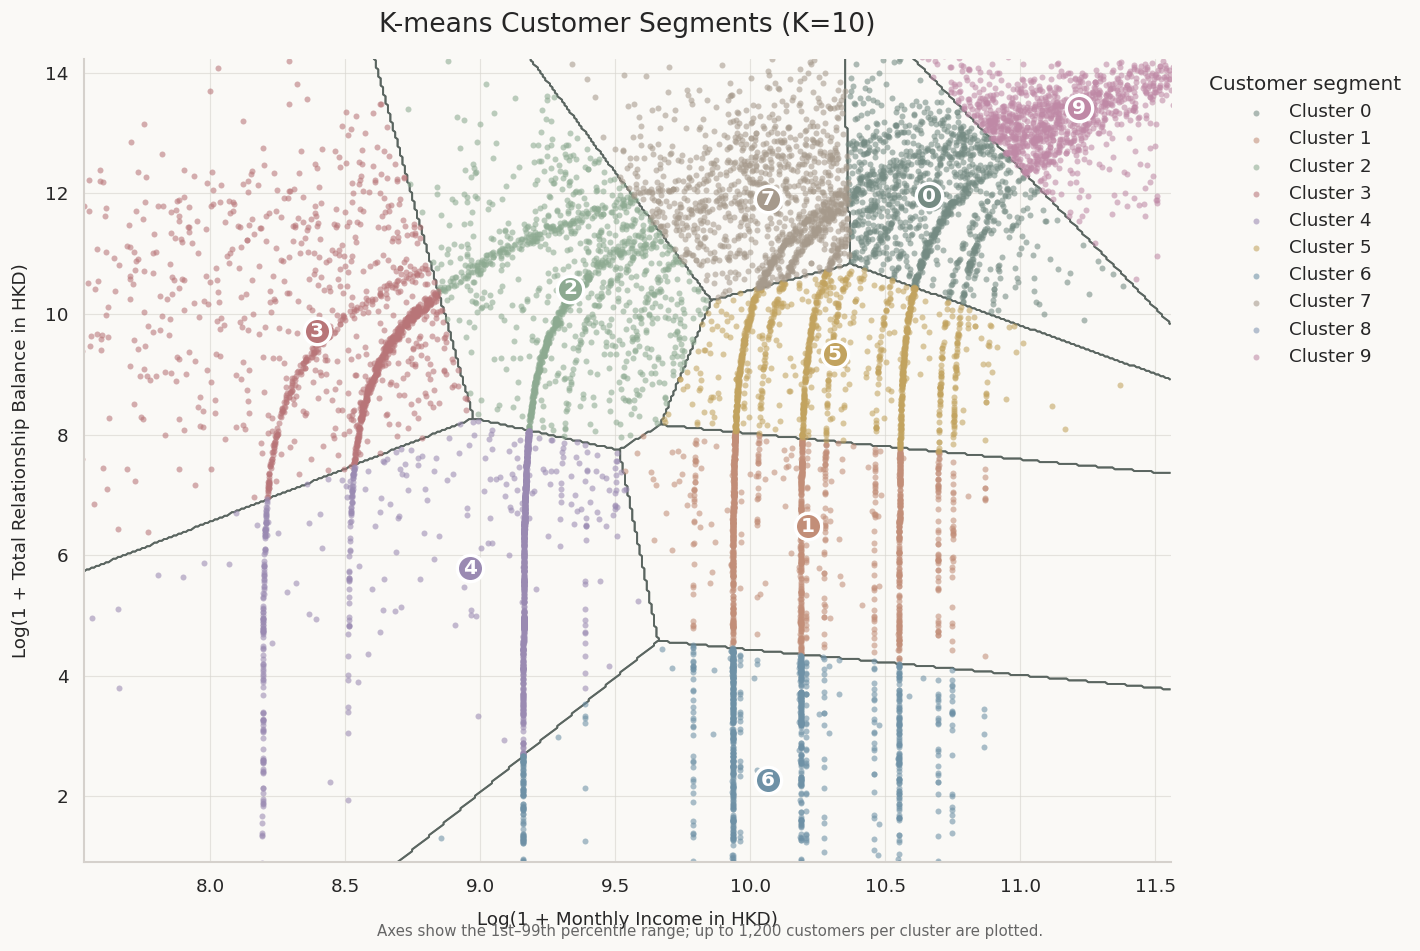

In [29]:
from matplotlib.colors import ListedColormap, BoundaryNorm

q4_colors = [
    "#758B83", "#C28E78", "#8DAA91", "#B87578", "#9A8AB2",
    "#C2A35F", "#6E91A6", "#A69A8C", "#8296B2", "#BF89A6"
]
q4_cmap = ListedColormap(q4_colors)
q4_norm = BoundaryNorm(np.arange(-0.5, 10.5, 1), q4_cmap.N)

q4_plot_data = pd.DataFrame({
    "Log Income": np.log1p(df_analysis["INCOME"]),
    "Log TRB": np.log1p(df_analysis["TRB"]),
    "Cluster": df_analysis["KMEANS_K10"].astype(int)
})

# Keep the central 98% of each axis in view.
x_min, x_max = q4_plot_data["Log Income"].quantile([0.01, 0.99])
y_min, y_max = q4_plot_data["Log TRB"].quantile([0.01, 0.99])

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 450),
    np.linspace(y_min, y_max, 450)
)

grid_log = np.column_stack([xx.ravel(), yy.ravel()])
grid_scaled = q4_scaler.transform(grid_log)
grid_labels = q4_kmeans.predict(grid_scaled).reshape(xx.shape)

# Sample up to 1,200 customers from each cluster for a clearer scatter plot.
q4_plot_sample = (
    q4_plot_data
    .groupby("Cluster", group_keys=False)
    .apply(
        lambda group: group.sample(
            n=min(len(group), 1200),
            random_state=RANDOM_STATE
        ),
        include_groups=True
    )
)

fig, ax = plt.subplots(figsize=(12, 8), facecolor="#FAF9F6")
ax.set_facecolor("#FAF9F6")

# Keep the cluster regions as a light background.
for cluster_id in range(10):
    ax.contour(
        xx,
        yy,
        (grid_labels == cluster_id).astype(int),
        levels=[0.5],
        colors=["#59645F"],
        linewidths=1.15,
        alpha=0.9,
        zorder=1
    )

# Plot sampled customer points using their cluster colors.
for cluster_id in range(10):
    cluster_points = q4_plot_sample[
        q4_plot_sample["Cluster"] == cluster_id
    ]
    ax.scatter(
        cluster_points["Log Income"],
        cluster_points["Log TRB"],
        color=q4_colors[cluster_id],
        s=13,
        alpha=0.58,
        linewidths=0,
        label=f"Cluster {cluster_id}",
        rasterized=True,
        zorder=2
    )

# Add cluster centers and labels.
centers_log = q4_scaler.inverse_transform(q4_kmeans.cluster_centers_)

for cluster_id, (center_x, center_y) in enumerate(centers_log):
    if x_min <= center_x <= x_max and y_min <= center_y <= y_max:
        ax.scatter(
            center_x,
            center_y,
            color=q4_colors[cluster_id],
            s=250,
            edgecolor="white",
            linewidth=2,
            zorder=5
        )
        ax.annotate(
            str(cluster_id),
            (center_x, center_y),
            xytext=(0, 0),
            textcoords="offset points",
            ha="center",
            va="center",
            color="white",
            fontsize=12,
            weight="bold",
            zorder=6
        )

ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_title("K-means Customer Segments (K=10)", fontsize=16, pad=16)
ax.set_xlabel("Log(1 + Monthly Income in HKD)", fontsize=11, labelpad=9)
ax.set_ylabel("Log(1 + Total Relationship Balance in HKD)", fontsize=11, labelpad=9)

ax.grid(color="#D9D6D0", linewidth=0.7, alpha=0.65)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    title="Customer segment",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
    ncol=1
)

fig.text(
    0.5,
    0.015,
    "Axes show the 1st–99th percentile range; up to 1,200 customers per cluster are plotted.",
    ha="center",
    fontsize=9,
    color="#666666"
)

save_figure(fig, "q4_kmeans_k10_scatter_colored")

## Q4(a). K-means Clustering Results


This K-means model used 47,882 customer records and a fixed value of 10 clusters. The clustering variables were monthly income (`INCOME`) and total relationship balance (`TRB`). Both monetary variables were transformed using `log(1+x)` and standardized before clustering. Age, digital-service use, and product-holding indicators were not used to form the clusters; they were used only to describe the resulting customer profiles.

| Cluster | Customers | Financial and customer profile |
|---|---:|---|
| 0 | 9,758 | Mean income was about HKD 43,367 and mean TRB about HKD 217,770. Customers aged 30–34 were relatively common, and credit-card holding was about 74%. This group can be described as higher-income customers with higher TRB. |
| 1 | 5,019 | Mean income was about HKD 28,374 and mean TRB about HKD 997. Digital banking activation was about 90%. This group can be described as middle-income customers with low TRB. |
| 2 | 5,077 | Mean income was about HKD 11,584 and mean TRB about HKD 63,898. MPF holding was about 41%. This group can be described as lower-income customers with higher TRB. |
| 3 | 1,944 | Mean income was about HKD 4,687 and mean TRB about HKD 47,241. About half were aged 18–24, and PayMe and MPF holding rates were relatively high. This group can be described as younger customers with lower income and higher TRB. |
| 4 | 2,012 | Mean income was about HKD 8,322 and mean TRB about HKD 764. Digital banking activation was about 24%, and credit-card holding was about 8%. This group can be described as lower-income customers with low TRB and lower digital-service use. |
| 5 | 9,908 | Mean income was about HKD 31,380 and mean TRB about HKD 14,612. Digital banking activation was about 91%, and credit-card holding was about 52%. This group can be described as middle-to-higher-income customers with lower TRB and active digital-service use. |
| 6 | 1,659 | Mean income was about HKD 25,531 and mean TRB about HKD 20. Credit-card holding was about 32%. This group can be described as middle-income customers whose TRB is close to zero. |
| 7 | 7,845 | Mean income was about HKD 24,006 and mean TRB about HKD 219,317. MPF holding was about 47%, and customers aged 30–34 were relatively common. This group can be described as middle-income customers with higher TRB and higher MPF holding. |
| 8 | 406 | Mean income was about HKD 789 and mean TRB about HKD 87,161. Customers aged 18–24 were relatively common. This small group can be described as low-income customers with relatively higher TRB, but should be interpreted cautiously. |
| 9 | 4,254 | Mean income was about HKD 80,765 and mean TRB about HKD 861,172. About 58% were aged 30–34, and credit-card holding was about 76%. This group can be described as high-income customers with high TRB. |

Overall, the ten clusters show different combinations of income and TRB. Clusters 0, 7, and 9 have higher mean TRB but differ in income and customer profiles. Clusters 1, 4, and 6 have very low mean TRB but differ in income and digital-service use. These differences describe the observed groups; because clustering used only income and TRB, age, digital-service use, and product holding are post-clustering profiles and should not be interpreted as causes of cluster membership. Cluster 8 is small and should be interpreted with particular caution.


As a supplementary analysis for mixed-type data, K-prototypes is applied using `INCOME` and `TRB` as numerical variables, and `AGE` plus all binary fields as categorical variables. The two monetary variables use the same `log(1+x)` transformation and standardization as in K-means; age bands and binary fields are treated as categorical.

The number of clusters is fixed at 10 to complement the Q4 K-means results. Since the two methods use different types of variables, differences between their results reflect different segmentation approaches and cannot be attributed to the clustering algorithm alone. The choice of the best number of clusters is reserved for Q5.

In [20]:
q4_kproto_numeric_cols = ["INCOME", "TRB"]
q4_kproto_categorical_cols = ["AGE"] + BINARY_COLS

q4_kproto_numeric = df_analysis[q4_kproto_numeric_cols].copy()
q4_kproto_numeric = np.log1p(q4_kproto_numeric)

q4_kproto_scaler = StandardScaler()
q4_kproto_numeric_scaled = q4_kproto_scaler.fit_transform(
    q4_kproto_numeric
)

q4_kproto_categorical = (
    df_analysis[q4_kproto_categorical_cols]
    .astype("string")
    .fillna("Missing")
)

q4_kproto_data = pd.DataFrame(
    q4_kproto_numeric_scaled,
    columns=q4_kproto_numeric_cols,
    index=df_analysis.index
).join(q4_kproto_categorical)

q4_kproto_array = q4_kproto_data.to_numpy(dtype=object)
q4_kproto_categorical_indices = [
    q4_kproto_data.columns.get_loc(col)
    for col in q4_kproto_categorical_cols
]

print("K-prototypes input shape:", q4_kproto_array.shape)
print("Numerical variables:", q4_kproto_numeric_cols)
print("Categorical variables:", q4_kproto_categorical_cols)
print("Categorical column positions:", q4_kproto_categorical_indices)
print("Missing values:", int(q4_kproto_data.isna().sum().sum()))

K-prototypes input shape: (47882, 14)
Numerical variables: ['INCOME', 'TRB']
Categorical variables: ['AGE', 'DIG_ACTIVE', 'FX_TRANS', 'PAYME', 'CC', 'LN', 'MT', 'TD', 'SC', 'SP', 'BD', 'MPF']
Categorical column positions: [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
Missing values: 0


In [22]:
print("Current analysis records:", len(df_analysis))
print("K-prototypes input shape:", q4_kproto_array.shape)

assert len(df_analysis) == 47882, "请先检查 Q3 的排除条件"
assert len(q4_kproto_array) == len(df_analysis), (
    "聚类输入与当前样本数量不一致，请重新运行 K-prototypes 数据准备单元格"
)

Current analysis records: 47882
K-prototypes input shape: (47882, 14)


In [24]:
from kmodes.kprototypes import KPrototypes

q4_kproto_model = KPrototypes(
    n_clusters=10,
    init="Cao",
    n_init=10,
    max_iter=100,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

df_analysis["KPROTOTYPES_K10"] = q4_kproto_model.fit_predict(
    q4_kproto_array,
    categorical=q4_kproto_categorical_indices
)

q4_kproto_cluster_sizes = (
    df_analysis["KPROTOTYPES_K10"]
    .value_counts()
    .sort_index()
    .rename("Customers")
    .to_frame()
)

print("K-prototypes clusters: 10")
print("K-prototypes cost:", round(q4_kproto_model.cost_, 3))
display(q4_kproto_cluster_sizes)

Initialization method and algorithm are deterministic. Setting n_init to 1.
Init: initializing centroids
Init: initializing centroids
Init: initializing centroids
Init: initializing centroids
Init: initializing centroids
Init: initializing centroids
Init: initializing centroids
Init: initializing centroids
Init: initializing clusters
Init: initializing clusters
Init: initializing clusters
Init: initializing clusters
Init: initializing clusters
Init: initializing clusters
Init: initializing clusters
Init: initializing clusters
Starting iterations...
Starting iterations...
Starting iterations...
Starting iterations...
Starting iterations...
Starting iterations...
Starting iterations...
Starting iterations...
Run: 1, iteration: 1/100, moves: 17713, ncost: 67812.04356331509
Run: 8, iteration: 1/100, moves: 20720, ncost: 68813.21575382297
Run: 4, iteration: 1/100, moves: 21585, ncost: 70490.85699140046
Run: 7, iteration: 1/100, moves: 20859, ncost: 65558.80372430515
Run: 6, iteration: 1/100

,Customers
KPROTOTYPES_K10,
0,6989
1,2972
2,1908
3,3639
4,8305
5,5605
6,6882
7,615
8,7717



K-prototypes used income and TRB as numerical variables, and age band and binary fields as categorical variables. The model was set to 10 clusters, with cluster sizes ranging from 615 to 8,305 customers. The next step is to summarize each cluster’s financial measures, age composition, digital-service use, and product holding, then compare the resulting profiles with those from K-means.

The K-prototypes cost and K-means inertia use different distance calculations and should not be compared directly.

In [25]:
q4_kproto_binary_cols = [
    col for col in BINARY_COLS
    if col in df_analysis.columns
]

q4_kproto_financial_profile = (
    df_analysis
    .groupby("KPROTOTYPES_K10")
    .agg(
        Customers=("KPROTOTYPES_K10", "size"),
        Mean_Income_HKD=("INCOME", "mean"),
        Median_Income_HKD=("INCOME", "median"),
        Mean_TRB_HKD=("TRB", "mean"),
        Median_TRB_HKD=("TRB", "median")
    )
)

q4_kproto_age_profile = (
    pd.crosstab(
        df_analysis["KPROTOTYPES_K10"],
        df_analysis["AGE"],
        normalize="index"
    )
    .mul(100)
    .rename(columns=lambda age: f"AGE_{age}_Percent")
)

q4_kproto_binary_profile = (
    df_analysis
    .groupby("KPROTOTYPES_K10")[q4_kproto_binary_cols]
    .mean()
    .mul(100)
    .rename(columns=lambda col: f"{col}_Percent")
)

q4_kproto_profile = (
    q4_kproto_financial_profile
    .join(q4_kproto_age_profile)
    .join(q4_kproto_binary_profile)
)

display(q4_kproto_profile.round(2))

,Customers,Mean_Income_HKD,Median_Income_HKD,Mean_TRB_HKD,Median_TRB_HKD,AGE_18-24_Percent,AGE_25-29_Percent,AGE_30-34_Percent,DIG_ACTIVE_Percent,FX_TRANS_Percent,PAYME_Percent,CC_Percent,LN_Percent,MT_Percent,TD_Percent,SC_Percent,SP_Percent,BD_Percent,MPF_Percent
KPROTOTYPES_K10,,,,,,,,,,,,,,,,,,,
0,6989,39340.28,39223.35,25914.00,17249.10,25.53,26.30,48.18,92.14,26.30,79.88,92.36,7.35,7.74,5.92,7.08,5.05,5.77,8.70
1,2972,12272.97,11097.64,48112.52,19943.70,21.33,23.01,55.65,22.71,15.65,16.02,13.06,5.89,5.01,7.50,9.22,4.88,5.55,13.09
2,1908,8561.51,9506.52,418.46,186.42,28.83,31.50,39.68,13.63,11.58,26.36,6.55,5.19,3.98,5.56,5.35,5.08,5.24,7.55
3,3639,7850.73,7215.23,63166.48,29220.45,50.37,28.69,20.94,87.63,16.93,85.38,22.84,6.02,6.13,8.00,8.77,4.75,6.24,64.99
4,8305,64094.22,55843.77,578530.70,400333.45,13.52,24.35,62.13,91.70,36.20,77.70,80.42,10.34,13.65,15.35,15.74,5.09,10.96,27.45
5,5605,30407.35,28888.40,152770.51,99963.48,22.16,47.65,30.19,86.05,24.51,32.42,12.79,7.81,6.65,11.65,10.63,4.76,6.90,10.56
6,6882,24219.73,22177.53,9142.58,4544.56,58.04,22.54,19.43,92.95,19.92,72.20,16.04,5.35,5.29,5.70,5.20,5.03,5.04,10.39
7,615,1223.56,1176.77,76941.36,32220.10,56.59,23.41,20.00,79.51,23.09,69.59,36.10,6.83,5.53,11.38,11.06,4.88,7.97,32.36
8,7717,27969.27,27117.28,231373.78,157935.76,16.09,51.63,32.28,93.04,28.11,89.81,82.05,10.43,8.79,12.00,12.85,5.17,9.15,82.09


Because K-prototypes uses multiple numerical and categorical variables, the original data cannot be shown directly in a two-dimensional scatter plot. For this figure, the categorical variables are one-hot encoded and PCA projects all input variables into two dimensions. PCA is used for visualization only and does not change the K-prototypes clustering results.

Points are colored by cluster. Shaded ellipses summarize each cluster’s spread in the two-dimensional projection, and circles mark the cluster centers in that projected space. The ellipses are not K-prototypes decision boundaries, and the PCA projection may compress or hide some differences in the original variables.

PCA input variables: ['INCOME', 'TRB', 'AGE_18-24', 'AGE_25-29', 'AGE_30-34', 'DIG_ACTIVE', 'FX_TRANS', 'PAYME', 'CC', 'LN', 'MT', 'TD', 'SC', 'SP', 'BD', 'MPF']
Customers: 47882
Explained variance: [34.5  17.54]


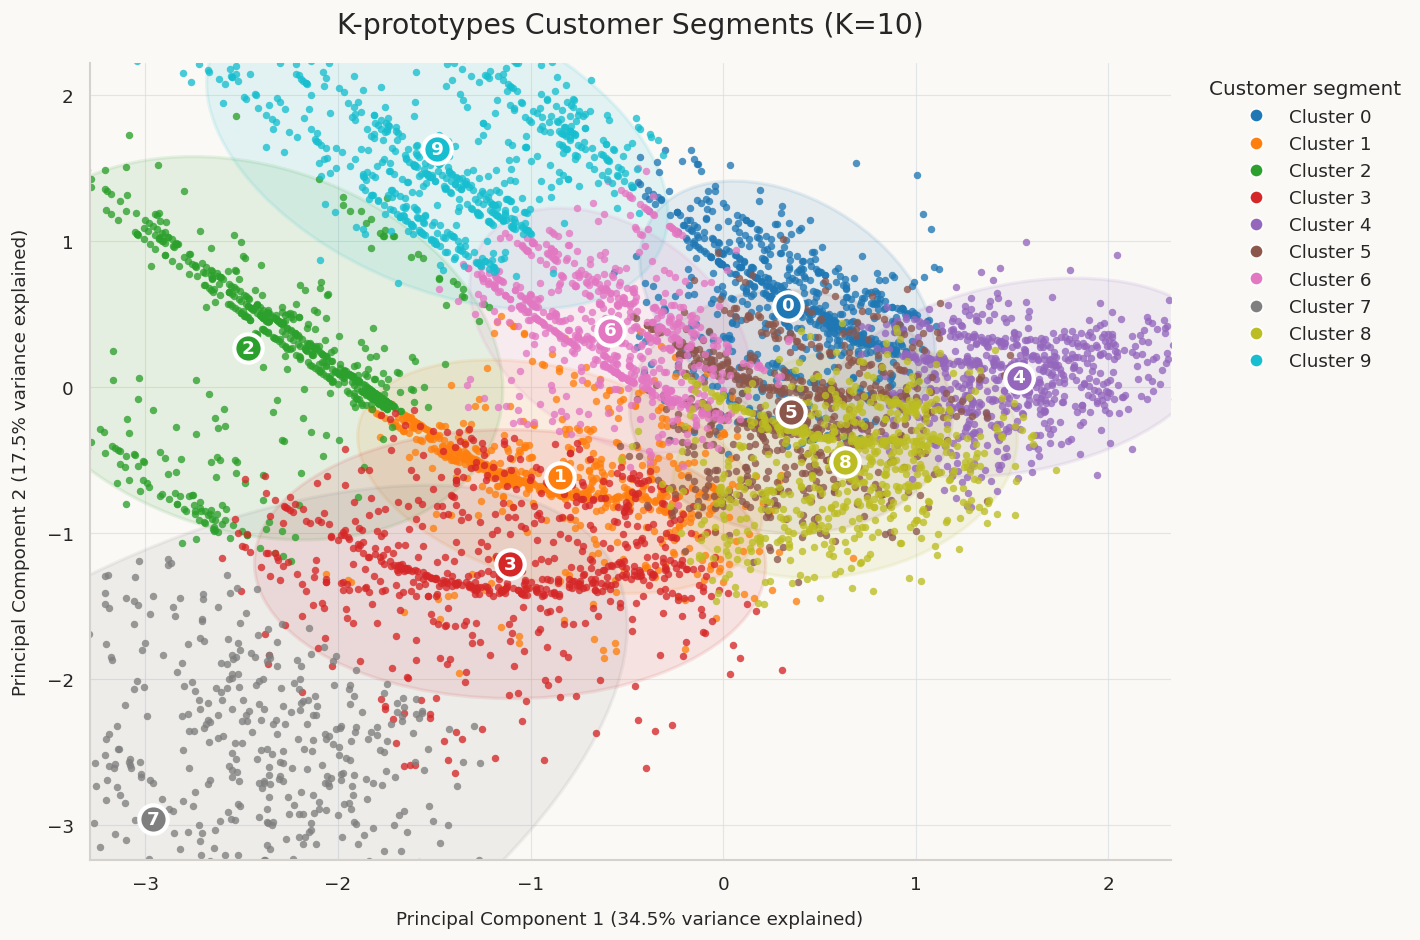

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from matplotlib.patches import Ellipse
from matplotlib.lines import Line2D
from scipy.stats import chi2

# ============================================================
# 1. Prepare all clustering variables for PCA visualization.
# ============================================================

# Standardize log-transformed income and TRB.
numeric_cols = ["INCOME", "TRB"]
numeric_scaled = StandardScaler().fit_transform(
    np.log1p(df_analysis[numeric_cols])
)

numeric_features = pd.DataFrame(
    numeric_scaled,
    columns=numeric_cols,
    index=df_analysis.index
)

# One-hot encode age; retain binary indicators as 0/1.
age_features = pd.get_dummies(
    df_analysis["AGE"].astype("string").fillna("Missing"),
    prefix="AGE",
    dtype=float
)

binary_features = df_analysis[BINARY_COLS].astype(float)

q4_kproto_pca_features = pd.concat(
    [numeric_features, age_features, binary_features],
    axis=1
)

# Use the existing K-prototypes labels.
q4_kproto_pca = PCA(n_components=2)
pca_coordinates = q4_kproto_pca.fit_transform(
    q4_kproto_pca_features
)

q4_kproto_pca_plot = pd.DataFrame(
    pca_coordinates,
    columns=["PC1", "PC2"],
    index=df_analysis.index
)
q4_kproto_pca_plot["Cluster"] = (
    df_analysis["KPROTOTYPES_K10"].astype(int)
)

print("PCA input variables:", q4_kproto_pca_features.columns.tolist())
print("Customers:", len(q4_kproto_pca_plot))
print(
    "Explained variance:",
    np.round(q4_kproto_pca.explained_variance_ratio_ * 100, 2)
)

# ============================================================
# 2. Plot with the original palette and warm background.
# ============================================================

q4_colors = plt.get_cmap("tab10").colors
background_color = "#FAF9F6"

fig, ax = plt.subplots(
    figsize=(12, 8),
    facecolor=background_color
)
ax.set_facecolor(background_color)

scale = np.sqrt(chi2.ppf(0.90, df=2))

for cluster_id in range(10):
    cluster_data = q4_kproto_pca_plot.loc[
        q4_kproto_pca_plot["Cluster"] == cluster_id,
        ["PC1", "PC2"]
    ]

    if cluster_data.empty:
        continue

    cluster_points = cluster_data.to_numpy()
    center = cluster_points.mean(axis=0)

    if len(cluster_data) >= 2:
        covariance = np.cov(cluster_points, rowvar=False)

        eigenvalues, eigenvectors = np.linalg.eigh(covariance)
        order = eigenvalues.argsort()[::-1]
        eigenvalues = np.maximum(eigenvalues[order], 0)
        eigenvectors = eigenvectors[:, order]

        angle = np.degrees(
            np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0])
        )

        ellipse = Ellipse(
            xy=center,
            width=2 * scale * np.sqrt(eigenvalues[0]),
            height=2 * scale * np.sqrt(eigenvalues[1]),
            angle=angle,
            facecolor=q4_colors[cluster_id],
            edgecolor=q4_colors[cluster_id],
            linewidth=2.0,
            alpha=0.10,
            zorder=1
        )
        ax.add_patch(ellipse)

    cluster_sample = cluster_data.sample(
        n=min(len(cluster_data), 700),
        random_state=RANDOM_STATE
    )

    ax.scatter(
        cluster_sample["PC1"],
        cluster_sample["PC2"],
        color=q4_colors[cluster_id],
        s=20,
        alpha=0.78,
        linewidths=0,
        rasterized=True,
        zorder=2
    )

    ax.scatter(
        center[0],
        center[1],
        s=290,
        color=q4_colors[cluster_id],
        edgecolor="white",
        linewidth=2.5,
        zorder=5
    )

    ax.text(
        center[0],
        center[1],
        str(cluster_id),
        ha="center",
        va="center",
        color="white",
        fontsize=11,
        weight="bold",
        zorder=6
    )

q4_centers_2d = (
    q4_kproto_pca_plot
    .groupby("Cluster")[["PC1", "PC2"]]
    .mean()
)

x_low, x_high = q4_kproto_pca_plot["PC1"].quantile([0.01, 0.99])
y_low, y_high = q4_kproto_pca_plot["PC2"].quantile([0.01, 0.99])

x_padding = 0.06 * (x_high - x_low)
y_padding = 0.06 * (y_high - y_low)

ax.set_xlim(
    min(x_low, q4_centers_2d["PC1"].min() - x_padding),
    max(x_high, q4_centers_2d["PC1"].max() + x_padding)
)
ax.set_ylim(
    min(y_low, q4_centers_2d["PC2"].min() - y_padding),
    max(y_high, q4_centers_2d["PC2"].max() + y_padding)
)

ax.set_title(
    "K-prototypes Customer Segments (K=10)",
    fontsize=17,
    pad=18
)
ax.set_xlabel(
    f"Principal Component 1 "
    f"({q4_kproto_pca.explained_variance_ratio_[0]:.1%} variance explained)",
    fontsize=11,
    labelpad=10
)
ax.set_ylabel(
    f"Principal Component 2 "
    f"({q4_kproto_pca.explained_variance_ratio_[1]:.1%} variance explained)",
    fontsize=11,
    labelpad=10
)

ax.grid(color="#D9DDE2", linewidth=0.7, alpha=0.7)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markerfacecolor=q4_colors[cluster_id],
        markeredgecolor="white",
        markersize=8,
        label=f"Cluster {cluster_id}"
    )
    for cluster_id in range(10)
]

ax.legend(
    handles=legend_handles,
    title="Customer segment",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

save_figure(fig, "q4_kprototypes_k10_pca_vivid")

### K-prototypes Cluster Profiles

K-prototypes used income, TRB, age band, and binary service/product fields. Its profiles therefore reflect financial, age, and product-use characteristics.

| Cluster | Summary profile |
|---|---|
| 0 | Higher income and moderate TRB; high credit-card holding (92%) and PayMe use (80%). |
| 1 | Lower income and relatively low TRB; low digital banking activation (23%) and a higher share of customers aged 30–34. |
| 2 | Lower income and near-zero TRB; low digital banking activation (14%) and PayMe use (26%). |
| 3 | Lower income and moderate TRB; about half are aged 18–24, with high PayMe use (85%) and MPF holding (65%). |
| 4 | High income and high TRB; mostly aged 30–34, with high credit-card holding (80%). This can be described as a high financial-value group. |
| 5 | Middle income and relatively high TRB; a larger share are aged 25–29, with lower PayMe use (32%) and credit-card holding (13%). |
| 6 | Middle income and lower TRB; mostly aged 18–24, with high digital banking activation (93%) but lower credit-card holding (16%). |
| 7 | Very low mean income and relatively high TRB; this is a small group of 615 customers and should be interpreted cautiously. |
| 8 | Middle income and relatively high TRB; high PayMe use (90%), credit-card holding (82%), and MPF holding (82%). |
| 9 | Middle income and near-zero TRB; digital banking activation is relatively high (88%), while holding rates for other products are generally lower. |

Compared with K-means using only income and TRB, K-prototypes includes age and service/product-use fields and therefore captures more differences in customer engagement and product holding. The two methods answer different questions: K-means segments customers by financial variables, while K-prototypes segments them using mixed-type variables. Their cost and inertia values are not directly comparable.

## Q5. Selecting the Number of Clusters

**K-prototypes analysis**

K-prototypes is also used as a supplementary analysis for mixed-type data. Following the report's variable selection, the clustering inputs are `INCOME`, `TRB`, `DIG_ACTIVE`, `PAYME`, and `FX_TRANS`. `AGE` and product-holding fields are reserved for post-clustering profiles and are not used as clustering inputs. The two monetary variables are transformed using `ln(1+x)` and then standardized using their means and sample standard deviations. The categorical weight is calculated as the ratio of average numerical variance to average categorical Gini impurity; for the current sample of 47,882 records, gamma is 2.7577.

K=2 to K=12 are compared using 50 distance-weighted initializations per K, with a maximum of 200 iterations. The solution with the lowest total within-cluster dissimilarity is retained. Silhouette scores are calculated on a fixed sample of 5,000 records using the same mixed distance as the clustering. K=7 has the highest silhouette score (0.5087), so it is selected for the supplementary K-prototypes analysis. Its cluster sizes, customer profiles, and business interpretation are then examined. K-prototypes cost and K-means inertia use different definitions and are not directly comparable.

In [30]:
from pathlib import Path
import pandas as pd

q3_file = Path.cwd() / "outputs" / "tables" / "HSBC_Q3_cleaned.xlsx"

if not q3_file.exists():
    raise FileNotFoundError(f"Could not find the Q3 cleaned workbook: {q3_file}")

df_analysis = pd.read_excel(
    q3_file,
    sheet_name="Analysis Data",
    index_col=0
)

print("Analysis sample shape:", df_analysis.shape)
print("Columns:", df_analysis.columns.tolist())

Analysis sample shape: (47882, 14)
Columns: ['AGE', 'INCOME', 'TRB', 'DIG_ACTIVE', 'FX_TRANS', 'PAYME', 'CC', 'LN', 'MT', 'TD', 'SC', 'SP', 'BD', 'MPF']


In [31]:
import numpy as np

ORIGINAL_COLS = [
    "AGE", "INCOME", "TRB", "DIG_ACTIVE", "FX_TRANS", "PAYME",
    "CC", "LN", "MT", "TD", "SC", "SP", "BD", "MPF"
]

MONEY_COLS = ["INCOME", "TRB"]
PRODUCT_COLS = ["CC", "LN", "MT", "TD", "SC", "SP", "BD", "MPF"]

q5_doc_numeric_cols = ["INCOME", "TRB"]
q5_doc_categorical_cols = ["DIG_ACTIVE", "PAYME", "FX_TRANS"]
q5_doc_profile_only_cols = ["AGE"] + PRODUCT_COLS
q5_doc_model_cols = q5_doc_numeric_cols + q5_doc_categorical_cols

if len(df_analysis) != 47882:
    raise ValueError(f"Expected 47882 records, found {len(df_analysis)}.")

missing_cols = [
    col for col in ORIGINAL_COLS
    if col not in df_analysis.columns
]
if missing_cols:
    raise ValueError(f"Missing expected columns: {missing_cols}")

if df_analysis[q5_doc_model_cols].isna().any().any():
    raise ValueError("Missing values found in the clustering input fields.")

if (df_analysis[q5_doc_numeric_cols] < 0).any().any():
    raise ValueError("Negative monetary values found before log transformation.")

print("Sample size:", len(df_analysis))
print("Clustering variables:", q5_doc_model_cols)
print("Profile-only variables:", q5_doc_profile_only_cols)
print("Data checks passed.")

Sample size: 47882
Clustering variables: ['INCOME', 'TRB', 'DIG_ACTIVE', 'PAYME', 'FX_TRANS']
Profile-only variables: ['AGE', 'CC', 'LN', 'MT', 'TD', 'SC', 'SP', 'BD', 'MPF']
Data checks passed.


In [32]:
# Apply log1p and standardize monetary variables
q5_doc_log_values = np.log1p(
    df_analysis[q5_doc_numeric_cols].astype(float)
)

q5_doc_means = q5_doc_log_values.mean()
q5_doc_sample_stds = q5_doc_log_values.std(ddof=1)

q5_doc_numeric_scaled = (
    (q5_doc_log_values - q5_doc_means)
    / q5_doc_sample_stds
)

# Calculate average variance of standardized numerical variables
q5_doc_avg_numeric_variance = (
    q5_doc_numeric_scaled.var(ddof=1).mean()
)

# Calculate Gini impurity for each categorical variable
q5_doc_gini_by_variable = {}

for col in q5_doc_categorical_cols:
    proportions = df_analysis[col].value_counts(normalize=True)
    q5_doc_gini_by_variable[col] = 1 - (proportions ** 2).sum()

q5_doc_avg_categorical_gini = np.mean(
    list(q5_doc_gini_by_variable.values())
)

# Calculate the categorical weight
q5_doc_gamma = (
    q5_doc_avg_numeric_variance
    / q5_doc_avg_categorical_gini
)

# Prepare the mixed-type input array
q5_doc_categorical_values = (
    df_analysis[q5_doc_categorical_cols]
    .astype(str)
    .reset_index(drop=True)
)

q5_doc_input = pd.concat(
    [
        q5_doc_numeric_scaled.reset_index(drop=True),
        q5_doc_categorical_values
    ],
    axis=1
)

q5_doc_array = q5_doc_input.to_numpy(dtype=object)

q5_doc_categorical_indices = [
    q5_doc_input.columns.get_loc(col)
    for col in q5_doc_categorical_cols
]

print("Average numerical variance:", q5_doc_avg_numeric_variance)
print("Average categorical Gini impurity:", q5_doc_avg_categorical_gini)
print("Calculated gamma:", q5_doc_gamma)
print("Prepared input shape:", q5_doc_array.shape)
print("Categorical column positions:", q5_doc_categorical_indices)

display(
    pd.DataFrame.from_dict(
        q5_doc_gini_by_variable,
        orient="index",
        columns=["Gini_Impurity"]
    )
)

Average numerical variance: 1.0000000000000002
Average categorical Gini impurity: 0.3626262384933048
Calculated gamma: 2.7576603506545854
Prepared input shape: (47882, 5)
Categorical column positions: [2, 3, 4]


,Gini_Impurity
DIG_ACTIVE,0.276597
PAYME,0.440971
FX_TRANS,0.370310


In [33]:
from joblib import Parallel, delayed
from sklearn.metrics import pairwise_distances, silhouette_score

q5_doc_numeric_array = q5_doc_numeric_scaled.to_numpy(dtype=float)
q5_doc_categorical_array = (
    df_analysis[q5_doc_categorical_cols]
    .to_numpy(dtype=int)
)

Q5_DOC_K_VALUES = list(range(2, 13))
Q5_DOC_N_INIT = 50
Q5_DOC_MAX_ITER = 200
Q5_DOC_N_JOBS = 4
Q5_DOC_SILHOUETTE_N = 5000


def q5_doc_point_to_prototype_costs(
    numeric_values,
    categorical_values,
    numeric_prototypes,
    categorical_prototypes,
    gamma
):
    numeric_costs = (
        (numeric_values[:, None, :] - numeric_prototypes[None, :, :]) ** 2
    ).sum(axis=2)

    categorical_costs = (
        categorical_values[:, None, :]
        != categorical_prototypes[None, :, :]
    ).sum(axis=2)

    return numeric_costs + gamma * categorical_costs


def q5_doc_fit_one_start(k, seed):
    rng = np.random.default_rng(seed)
    n_rows = len(q5_doc_numeric_array)

    selected_indices = [int(rng.integers(n_rows))]

    numeric_prototypes = [
        q5_doc_numeric_array[selected_indices[0]].copy()
    ]
    categorical_prototypes = [
        q5_doc_categorical_array[selected_indices[0]].copy()
    ]

    closest_cost = q5_doc_point_to_prototype_costs(
        q5_doc_numeric_array,
        q5_doc_categorical_array,
        np.asarray(numeric_prototypes),
        np.asarray(categorical_prototypes),
        q5_doc_gamma
    )[:, 0]

    while len(selected_indices) < k:
        weights = closest_cost.copy()
        weights[selected_indices] = 0

        if weights.sum() <= 0:
            remaining = np.setdiff1d(
                np.arange(n_rows),
                np.asarray(selected_indices),
                assume_unique=False
            )
            next_index = int(rng.choice(remaining))
        else:
            probabilities = weights / weights.sum()
            next_index = int(rng.choice(n_rows, p=probabilities))

        selected_indices.append(next_index)
        numeric_prototypes.append(
            q5_doc_numeric_array[next_index].copy()
        )
        categorical_prototypes.append(
            q5_doc_categorical_array[next_index].copy()
        )

        new_cost = q5_doc_point_to_prototype_costs(
            q5_doc_numeric_array,
            q5_doc_categorical_array,
            q5_doc_numeric_array[[next_index]],
            q5_doc_categorical_array[[next_index]],
            q5_doc_gamma
        )[:, 0]

        closest_cost = np.minimum(closest_cost, new_cost)

    numeric_prototypes = np.asarray(numeric_prototypes)
    categorical_prototypes = np.asarray(categorical_prototypes)

    previous_labels = None

    for iteration in range(Q5_DOC_MAX_ITER):
        costs = q5_doc_point_to_prototype_costs(
            q5_doc_numeric_array,
            q5_doc_categorical_array,
            numeric_prototypes,
            categorical_prototypes,
            q5_doc_gamma
        )

        labels = costs.argmin(axis=1)
        minimum_costs = costs[np.arange(n_rows), labels]

        new_numeric_prototypes = numeric_prototypes.copy()
        new_categorical_prototypes = categorical_prototypes.copy()

        empty_clusters = []

        for cluster_id in range(k):
            members = labels == cluster_id

            if not members.any():
                empty_clusters.append(cluster_id)
                continue

            new_numeric_prototypes[cluster_id] = (
                q5_doc_numeric_array[members].mean(axis=0)
            )

            for column_id in range(
                q5_doc_categorical_array.shape[1]
            ):
                counts = np.bincount(
                    q5_doc_categorical_array[members, column_id],
                    minlength=2
                )
                new_categorical_prototypes[
                    cluster_id, column_id
                ] = counts.argmax()

        if empty_clusters:
            farthest_indices = np.argsort(minimum_costs)[::-1]
            used_indices = set()

            for cluster_id in empty_clusters:
                for row_index in farthest_indices:
                    if int(row_index) not in used_indices:
                        used_indices.add(int(row_index))
                        new_numeric_prototypes[cluster_id] = (
                            q5_doc_numeric_array[row_index]
                        )
                        new_categorical_prototypes[cluster_id] = (
                            q5_doc_categorical_array[row_index]
                        )
                        break

        labels_unchanged = (
            previous_labels is not None
            and np.array_equal(labels, previous_labels)
        )

        numeric_prototypes = new_numeric_prototypes
        categorical_prototypes = new_categorical_prototypes
        previous_labels = labels.copy()

        if labels_unchanged:
            break

    final_costs = q5_doc_point_to_prototype_costs(
        q5_doc_numeric_array,
        q5_doc_categorical_array,
        numeric_prototypes,
        categorical_prototypes,
        q5_doc_gamma
    )

    final_labels = final_costs.argmin(axis=1)
    total_cost = final_costs[
        np.arange(n_rows), final_labels
    ].sum()

    return {
        "cost": float(total_cost),
        "labels": final_labels,
        "iterations": iteration + 1
    }


q5_doc_labels_by_k = {}
q5_doc_metrics_rows = []

# Build one fixed silhouette sample for every K
q5_doc_rng = np.random.default_rng(RANDOM_STATE)
q5_doc_sample_indices = q5_doc_rng.choice(
    len(df_analysis),
    size=min(Q5_DOC_SILHOUETTE_N, len(df_analysis)),
    replace=False
)

q5_doc_numeric_sample = q5_doc_numeric_array[
    q5_doc_sample_indices
]
q5_doc_categorical_sample = q5_doc_categorical_array[
    q5_doc_sample_indices
]

q5_doc_distance = pairwise_distances(
    q5_doc_numeric_sample,
    metric="sqeuclidean"
).astype(np.float32)

q5_doc_mismatch = np.zeros(
    q5_doc_distance.shape,
    dtype=np.uint8
)

for column_id in range(q5_doc_categorical_sample.shape[1]):
    q5_doc_mismatch += (
        q5_doc_categorical_sample[:, column_id, None]
        != q5_doc_categorical_sample[None, :, column_id]
    )

q5_doc_distance += (
    q5_doc_gamma * q5_doc_mismatch
).astype(np.float32)

print("Mixed-distance matrix shape:", q5_doc_distance.shape)
print("Mixed-distance matrix type:", q5_doc_distance.dtype)


for k in Q5_DOC_K_VALUES:
    start_time = time.perf_counter()
    seed_start = 17000 + 100 * k
    seeds = range(seed_start, seed_start + Q5_DOC_N_INIT)

    start_results = Parallel(n_jobs=Q5_DOC_N_JOBS)(
        delayed(q5_doc_fit_one_start)(k, seed)
        for seed in seeds
    )

    best_result = min(start_results, key=lambda result: result["cost"])
    labels = best_result["labels"]

    q5_doc_labels_by_k[k] = labels

    sample_labels = labels[q5_doc_sample_indices]
    silhouette = silhouette_score(
        q5_doc_distance,
        sample_labels,
        metric="precomputed"
    )

    cluster_sizes = pd.Series(labels).value_counts()

    q5_doc_metrics_rows.append({
        "K": k,
        "Cost": best_result["cost"],
        "Silhouette_Score": silhouette,
        "Min_Cluster_Size": int(cluster_sizes.min()),
        "Min_Cluster_Share_Percent": (
            cluster_sizes.min() / len(labels) * 100
        ),
        "Best_Run_Iterations": best_result["iterations"],
        "Fit_Time_Min": (time.perf_counter() - start_time) / 60
    })

    print(
        f"K={k} completed; "
        f"best cost={best_result['cost']:.2f}; "
        f"silhouette={silhouette:.4f}",
        flush=True
    )


q5_doc_metrics = (
    pd.DataFrame(q5_doc_metrics_rows)
    .set_index("K")
)

display(q5_doc_metrics.round(4))

Mixed-distance matrix shape: (5000, 5000)
Mixed-distance matrix type: float32
K=2 completed; best cost=147290.09; silhouette=0.4031
K=3 completed; best cost=119936.89; silhouette=0.3619
K=4 completed; best cost=98955.65; silhouette=0.4221
K=5 completed; best cost=83419.11; silhouette=0.4267
K=6 completed; best cost=70973.60; silhouette=0.4708
K=7 completed; best cost=64130.40; silhouette=0.5087
K=8 completed; best cost=58763.47; silhouette=0.4396
K=9 completed; best cost=55060.98; silhouette=0.4555
K=10 completed; best cost=50248.95; silhouette=0.4548
K=11 completed; best cost=46675.75; silhouette=0.4772
K=12 completed; best cost=44003.80; silhouette=0.4723


,Cost,Silhouette_Score,Min_Cluster_Size,Min_Cluster_Share_Percent,Best_Run_Iterations,Fit_Time_Min
K,,,,,,
2,147290.0870,0.4031,15997,33.4092,11,0.0422
3,119936.8860,0.3619,10440,21.8036,42,0.0449
4,98955.6464,0.4221,5881,12.2823,18,0.0514
5,83419.1075,0.4267,5513,11.5137,40,0.0608
6,70973.5989,0.4708,3892,8.1283,21,0.0657
7,64130.4023,0.5087,2831,5.9125,29,0.0804
8,58763.4680,0.4396,2820,5.8895,46,0.0860
9,55060.9770,0.4555,2373,4.9559,58,0.0966
10,50248.9545,0.4548,1883,3.9326,64,0.1051


## Selecting the Number of Clusters

After considering the four metrics across K=2 to K=12, K=7 is selected.

- **Cost** decreases as the number of clusters increases, which is expected and does not determine K on its own. The relative reduction plot shows that the larger cost improvements occur at lower K values; the reductions generally become smaller as more clusters are added.
- The **silhouette score** reaches its highest value at K=7 (**0.5087**), indicating the strongest overall within-cluster cohesion and between-cluster separation among the solutions tested.
- The **smallest cluster share** at K=7 is **5.9%**, representing **2,831 records**—a sufficiently substantial group for profiling and business discussion.
- Although cost continues to fall at higher K values, their silhouette scores do not exceed the K=7 result, and their smallest clusters become smaller. K=7 therefore provides a suitable balance between clustering quality, group size, and level of segmentation.

The following customer profiles and business interpretation are based on the K=7 solution.

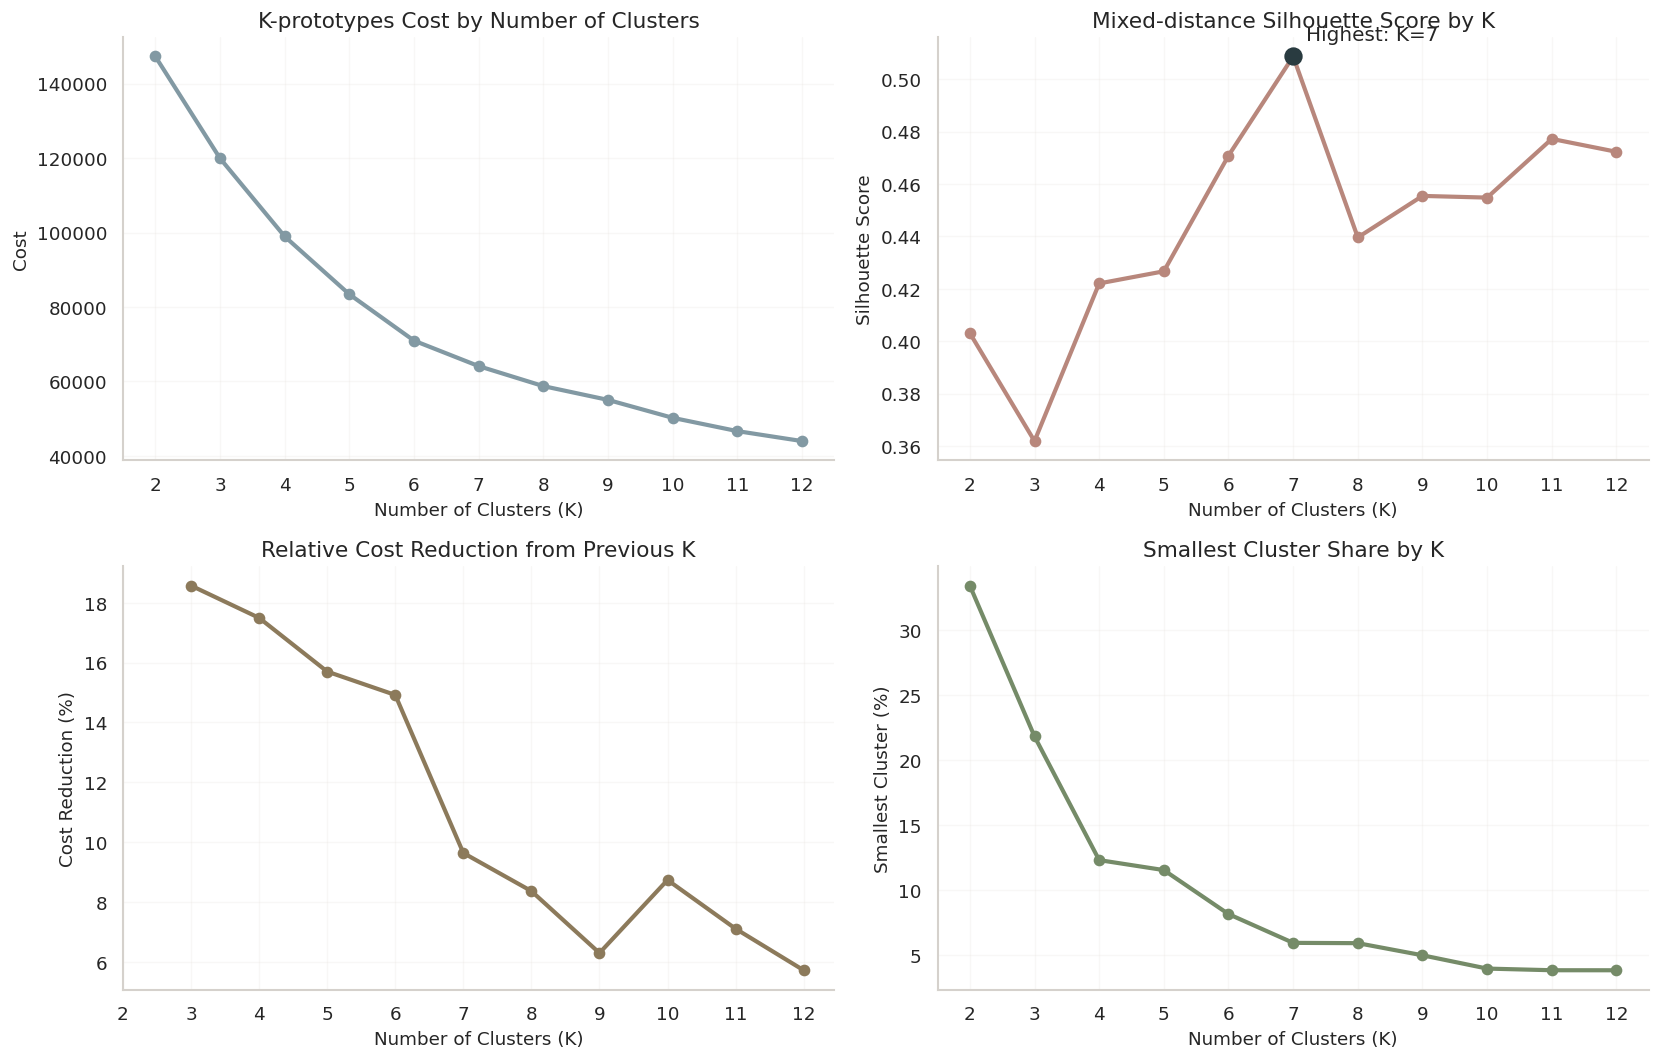

In [34]:
q5_doc_plot_metrics = q5_doc_metrics.copy()

q5_doc_plot_metrics["Relative_Cost_Reduction_Percent"] = (
    q5_doc_plot_metrics["Cost"].shift(1)
    .sub(q5_doc_plot_metrics["Cost"])
    .div(q5_doc_plot_metrics["Cost"].shift(1))
    .mul(100)
)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].plot(
    q5_doc_plot_metrics.index,
    q5_doc_plot_metrics["Cost"],
    marker="o",
    color="#8299A3",
    linewidth=2.5
)
axes[0, 0].set_title("K-prototypes Cost by Number of Clusters")
axes[0, 0].set_xlabel("Number of Clusters (K)")
axes[0, 0].set_ylabel("Cost")

axes[0, 1].plot(
    q5_doc_plot_metrics.index,
    q5_doc_plot_metrics["Silhouette_Score"],
    marker="o",
    color="#B8877C",
    linewidth=2.5
)
axes[0, 1].scatter(
    7,
    q5_doc_plot_metrics.loc[7, "Silhouette_Score"],
    s=100,
    color="#293B40",
    zorder=3
)
axes[0, 1].annotate(
    "Highest: K=7",
    (7, q5_doc_plot_metrics.loc[7, "Silhouette_Score"]),
    xytext=(8, 10),
    textcoords="offset points"
)
axes[0, 1].set_title("Mixed-distance Silhouette Score by K")
axes[0, 1].set_xlabel("Number of Clusters (K)")
axes[0, 1].set_ylabel("Silhouette Score")

axes[1, 0].plot(
    q5_doc_plot_metrics.index,
    q5_doc_plot_metrics["Relative_Cost_Reduction_Percent"],
    marker="o",
    color="#8C7A5B",
    linewidth=2.5
)
axes[1, 0].set_title("Relative Cost Reduction from Previous K")
axes[1, 0].set_xlabel("Number of Clusters (K)")
axes[1, 0].set_ylabel("Cost Reduction (%)")

axes[1, 1].plot(
    q5_doc_plot_metrics.index,
    q5_doc_plot_metrics["Min_Cluster_Share_Percent"],
    marker="o",
    color="#758B68",
    linewidth=2.5
)
axes[1, 1].set_title("Smallest Cluster Share by K")
axes[1, 1].set_xlabel("Number of Clusters (K)")
axes[1, 1].set_ylabel("Smallest Cluster (%)")

for ax in axes.flat:
    ax.set_xticks(q5_doc_plot_metrics.index)
    ax.grid(True, alpha=0.25)

save_figure(fig, "q5_document_method_kprototypes_metrics")

In [39]:
q5_doc_k7_data = df_analysis.copy()
q5_doc_k7_data["RAW_CLUSTER"] = q5_doc_labels_by_k[7]

# Order clusters by median monthly income and assign report labels G1-G7
q5_doc_k7_income_order = (
    q5_doc_k7_data
    .groupby("RAW_CLUSTER")["INCOME"]
    .median()
    .sort_values()
    .index
    .tolist()
)

q5_doc_k7_label_map = {
    raw_cluster: f"G{rank + 1}"
    for rank, raw_cluster in enumerate(q5_doc_k7_income_order)
}

q5_doc_k7_data["CLUSTER"] = (
    q5_doc_k7_data["RAW_CLUSTER"]
    .map(q5_doc_k7_label_map)
)

q5_doc_k7_cluster_order = [
    f"G{i}" for i in range(1, 8)
]

# Main profile, following the report's customer-profile table
q5_doc_k7_main_profile = (
    q5_doc_k7_data
    .groupby("CLUSTER")
    .agg(
        Customers=("CLUSTER", "size"),
        Median_Income_HKD=("INCOME", "median"),
        Median_TRB_HKD=("TRB", "median"),
        Digital_Banking_Rate_Percent=("DIG_ACTIVE", "mean"),
        PayMe_Rate_Percent=("PAYME", "mean"),
        FX_Transaction_Rate_Percent=("FX_TRANS", "mean")
    )
    .reindex(q5_doc_k7_cluster_order)
)

rate_cols = [
    "Digital_Banking_Rate_Percent",
    "PayMe_Rate_Percent",
    "FX_Transaction_Rate_Percent"
]

q5_doc_k7_main_profile[rate_cols] *= 100
q5_doc_k7_main_profile.insert(
    1,
    "Share_Percent",
    q5_doc_k7_main_profile["Customers"] / len(q5_doc_k7_data) * 100
)

print("K=7 profile sample size:", len(q5_doc_k7_data))
print("Cluster counts sum:", int(q5_doc_k7_main_profile["Customers"].sum()))
display(q5_doc_k7_main_profile.round(3))

# Additional profile: age composition and product-holding rates
q5_doc_k7_age_profile = (
    pd.crosstab(
        q5_doc_k7_data["CLUSTER"],
        q5_doc_k7_data["AGE"],
        normalize="index"
    )
    .reindex(index=q5_doc_k7_cluster_order, columns=AGE_ORDER, fill_value=0)
    .mul(100)
)
q5_doc_k7_age_profile.columns = [
    f"AGE_{age}_Percent" for age in q5_doc_k7_age_profile.columns
]

q5_doc_k7_product_profile = (
    q5_doc_k7_data
    .groupby("CLUSTER")[PRODUCT_COLS]
    .mean()
    .reindex(q5_doc_k7_cluster_order)
    .mul(100)
)
q5_doc_k7_product_profile.columns = [
    f"{col}_Percent" for col in q5_doc_k7_product_profile.columns
]

q5_doc_k7_additional_profile = q5_doc_k7_age_profile.join(
    q5_doc_k7_product_profile
)

display(q5_doc_k7_additional_profile.round(3))

K=7 profile sample size: 47882
Cluster counts sum: 47882


,Customers,Share_Percent,Median_Income_HKD,Median_TRB_HKD,Digital_Banking_Rate_Percent,PayMe_Rate_Percent,FX_Transaction_Rate_Percent
CLUSTER,,,,,,,
G1,3848,8.036,5556.828,21287.879,81.601,89.215,11.435
G2,4490,9.377,10098.741,3674.966,3.363,10.601,10.780
G3,5764,12.038,22807.414,457.062,94.067,83.119,8.189
G4,7482,15.626,29196.116,51449.275,91.607,0.000,0.000
G5,15946,33.303,33030.028,110423.984,93.428,100.000,0.000
G6,2831,5.912,36225.772,68358.082,87.813,0.000,100.000
G7,7521,15.707,37286.251,108613.834,92.980,100.000,100.000


,AGE_18-24_Percent,AGE_25-29_Percent,AGE_30-34_Percent,CC_Percent,LN_Percent,MT_Percent,TD_Percent,SC_Percent,SP_Percent,BD_Percent,MPF_Percent
CLUSTER,,,,,,,,,,,
G1,48.311,28.690,22.999,25.754,6.055,5.925,8.394,8.524,4.808,6.289,49.532
G2,27.506,30.356,42.138,16.058,5.390,4.543,5.657,6.927,4.655,5.323,10.290
G3,40.892,30.899,28.210,39.018,5.014,5.413,5.222,4.806,4.736,4.910,9.594
G4,28.789,30.807,40.404,41.927,6.963,7.551,9.810,9.102,5.079,6.536,23.964
G5,22.626,34.504,42.870,66.606,9.526,10.184,10.153,10.949,5.105,8.435,36.247
G6,28.400,30.095,41.505,42.776,6.959,6.641,12.081,11.904,5.722,6.676,21.123
G7,26.659,35.554,37.788,68.116,9.095,8.244,12.552,12.884,4.866,8.749,36.298


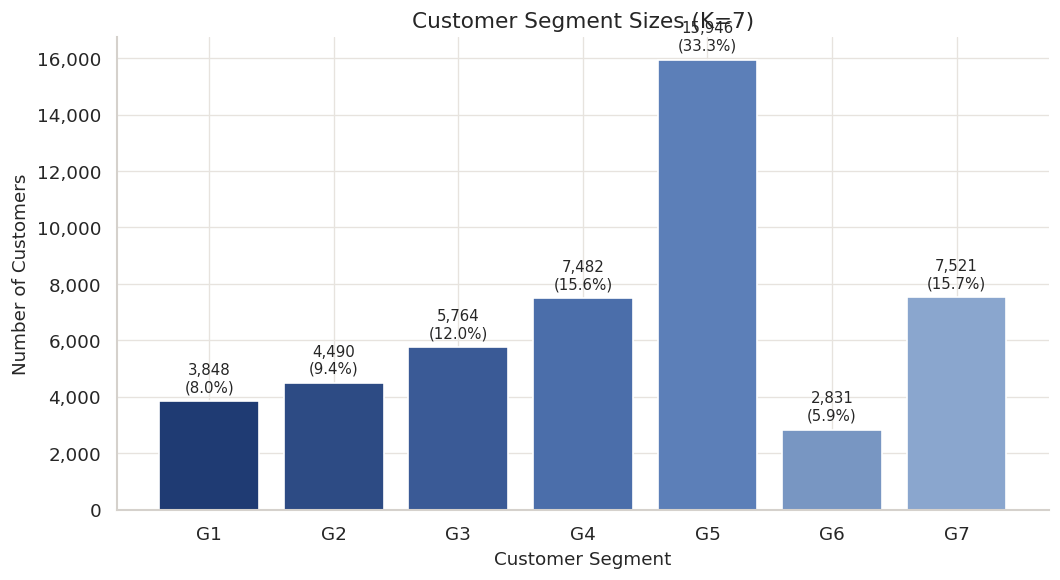

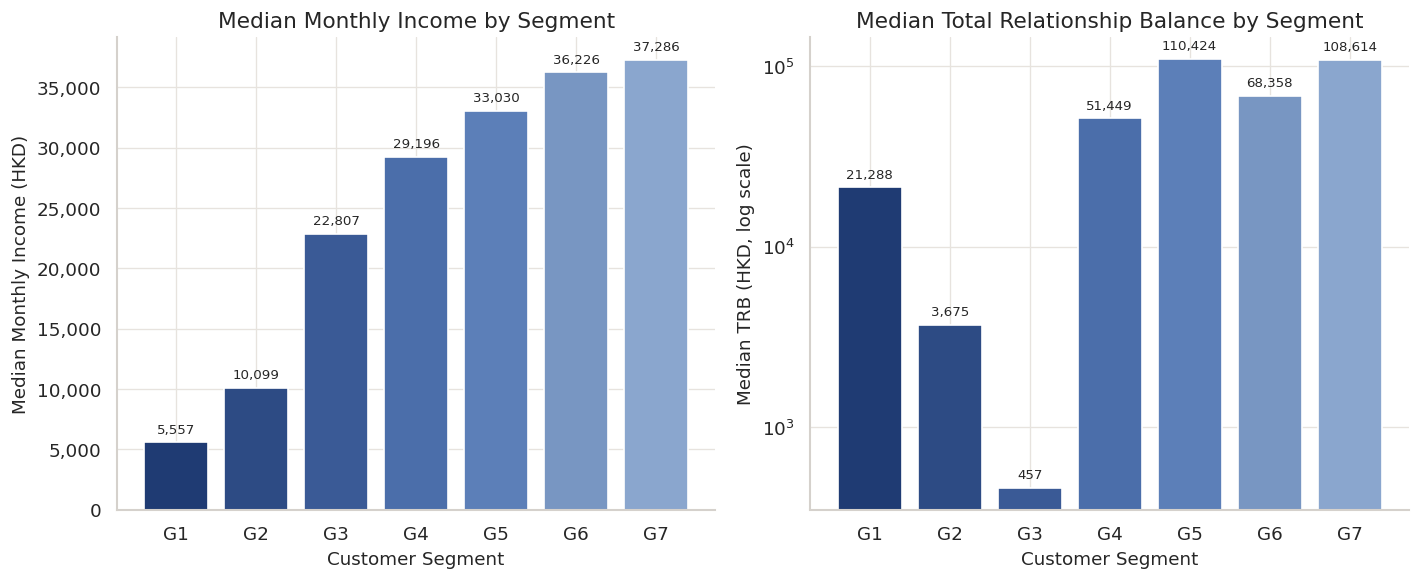

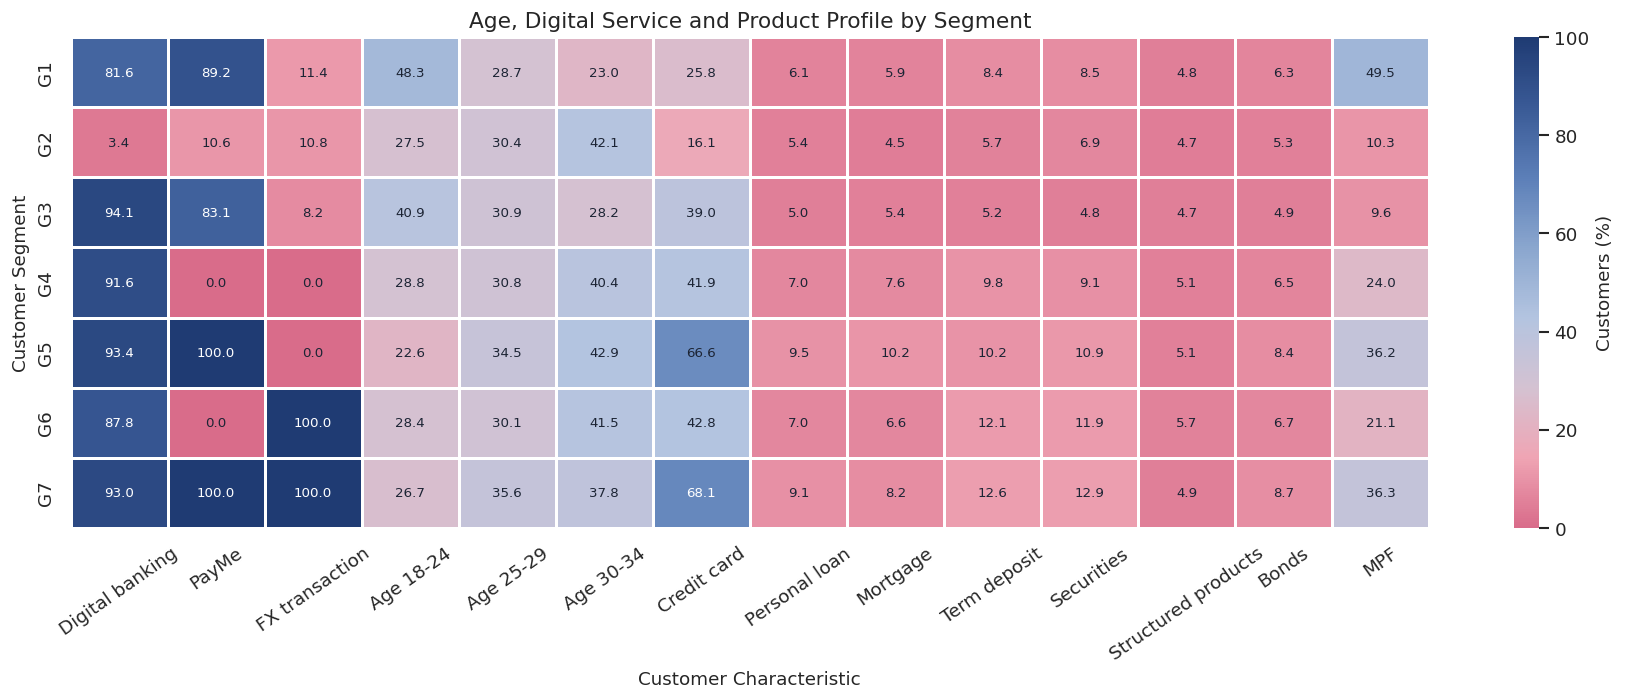

In [36]:
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.ticker import FuncFormatter

# Blue shades for the cluster bars
q5_doc_k7_blue_palette = [
    "#1F3B73",
    "#2D4B84",
    "#3A5A96",
    "#4B6EAA",
    "#5C7FB8",
    "#7896C2",
    "#8AA6CE"
]

# Blue-to-pink palette inspired by the reference image
q5_doc_k7_heatmap_cmap = LinearSegmentedColormap.from_list(
    "scientific_red_to_blue",
    [
        "#D96C8A",  # Low values: rose red
        "#EFA5B4",
        "#D4C2D2",
        "#B3C4E0",
        "#8AA6CE",
        "#5C7FB8",
        "#3A5A96",
        "#1F3B73"   # High values: deep blue
    ]
)

q5_doc_k7_plot_profile = q5_doc_k7_main_profile.copy()
cluster_labels = q5_doc_k7_cluster_order
cluster_colors = q5_doc_k7_blue_palette[:len(cluster_labels)]


# Chart 1: cluster sizes
fig, ax = plt.subplots(figsize=(9, 5), facecolor="white")
ax.set_facecolor("white")

bars = ax.bar(
    cluster_labels,
    q5_doc_k7_plot_profile.loc[cluster_labels, "Customers"],
    color=cluster_colors,
    edgecolor="white",
    linewidth=1
)

ax.set_title("Customer Segment Sizes (K=7)")
ax.set_xlabel("Customer Segment")
ax.set_ylabel("Number of Customers")
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}"))

for bar, cluster in zip(bars, cluster_labels):
    count = int(q5_doc_k7_plot_profile.loc[cluster, "Customers"])
    share = q5_doc_k7_plot_profile.loc[cluster, "Share_Percent"]
    ax.annotate(
        f"{count:,}\n({share:.1f}%)",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

save_figure(fig, "q5_k7_segment_sizes")


# Chart 2: median income and TRB
fig, axes = plt.subplots(1, 2, figsize=(12, 5), facecolor="white")

financial_charts = [
    (
        axes[0],
        "Median_Income_HKD",
        "Median Monthly Income by Segment",
        "Median Monthly Income (HKD)",
        False
    ),
    (
        axes[1],
        "Median_TRB_HKD",
        "Median Total Relationship Balance by Segment",
        "Median TRB (HKD, log scale)",
        True
    )
]

for ax, column, title, ylabel, use_log_scale in financial_charts:
    values = q5_doc_k7_plot_profile.loc[cluster_labels, column]

    ax.set_facecolor("white")
    bars = ax.bar(
        cluster_labels,
        values,
        color=cluster_colors,
        edgecolor="white",
        linewidth=1
    )

    ax.set_title(title)
    ax.set_xlabel("Customer Segment")
    ax.set_ylabel(ylabel)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}"))

    if use_log_scale:
        ax.set_yscale("log")

    for bar, value in zip(bars, values):
        ax.annotate(
            f"{value:,.0f}",
            (bar.get_x() + bar.get_width() / 2, value),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8
        )

save_figure(fig, "q5_k7_median_financial_profile")


# Chart 3: age, digital service, and product profile heatmap
q5_doc_k7_rate_cols = [
    "Digital_Banking_Rate_Percent",
    "PayMe_Rate_Percent",
    "FX_Transaction_Rate_Percent"
]

q5_doc_k7_heatmap_data = (
    q5_doc_k7_plot_profile.loc[cluster_labels, q5_doc_k7_rate_cols]
    .join(q5_doc_k7_additional_profile.loc[cluster_labels])
)

q5_doc_k7_heatmap_labels = {
    "Digital_Banking_Rate_Percent": "Digital banking",
    "PayMe_Rate_Percent": "PayMe",
    "FX_Transaction_Rate_Percent": "FX transaction",
    "AGE_18-24_Percent": "Age 18-24",
    "AGE_25-29_Percent": "Age 25-29",
    "AGE_30-34_Percent": "Age 30-34",
    "CC_Percent": "Credit card",
    "LN_Percent": "Personal loan",
    "MT_Percent": "Mortgage",
    "TD_Percent": "Term deposit",
    "SC_Percent": "Securities",
    "SP_Percent": "Structured products",
    "BD_Percent": "Bonds",
    "MPF_Percent": "MPF"
}

q5_doc_k7_heatmap_data = q5_doc_k7_heatmap_data.rename(
    columns=q5_doc_k7_heatmap_labels
)

fig, ax = plt.subplots(figsize=(15, 6), facecolor="white")
ax.set_facecolor("white")

sns.heatmap(
    q5_doc_k7_heatmap_data,
    annot=False,
    cmap=q5_doc_k7_heatmap_cmap,
    vmin=0,
    vmax=100,
    linewidths=0.7,
    linecolor="white",
    cbar_kws={"label": "Customers (%)"},
    ax=ax
)

# Add labels with contrast-adjusted text colors
for row_index in range(q5_doc_k7_heatmap_data.shape[0]):
    for column_index in range(q5_doc_k7_heatmap_data.shape[1]):
        value = q5_doc_k7_heatmap_data.iloc[row_index, column_index]
        red, green, blue, _ = q5_doc_k7_heatmap_cmap(value / 100)
        luminance = 0.2126 * red + 0.7152 * green + 0.0722 * blue
        text_color = "white" if luminance < 0.52 else "#1C2434"

        ax.text(
            column_index + 0.5,
            row_index + 0.5,
            f"{value:.1f}",
            ha="center",
            va="center",
            color=text_color,
            fontsize=8
        )

ax.set_title("Age, Digital Service and Product Profile by Segment")
ax.set_xlabel("Customer Characteristic")
ax.set_ylabel("Customer Segment")
ax.tick_params(axis="x", rotation=35)

save_figure(fig, "q5_k7_customer_profile_heatmap")

## Q6. Hierarchical Clustering

Hierarchical clustering uses the same 47,882-record analysis sample and five clustering variables as the Q5 K-prototypes analysis: `INCOME`, `TRB`, `DIG_ACTIVE`, `PAYME`, and `FX_TRANS`. The monetary variables retain the `ln(1+x)` transformation and sample standardization. Categorical variables are weighted according to the categorical weight before Ward clustering.

The full sample is used, with a 30-nearest-neighbour connectivity graph to manage computation. The dendrogram will collapse some terminal branches for readability, while the underlying hierarchy is built from the full sample. The tree will then be cut into seven groups so their profiles can be examined and compared with the Q5 K-prototypes results.

In [41]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import csr_matrix

q6_hier_numeric = q5_doc_numeric_scaled.to_numpy(dtype=float)
q6_hier_categorical = (
    df_analysis[q5_doc_categorical_cols]
    .to_numpy(dtype=float)
)

q6_hier_X = np.column_stack([
    q6_hier_numeric,
    q6_hier_categorical * np.sqrt(q5_doc_gamma)
])

q6_n_neighbors = HIERARCHY_NEIGHBORS

q6_neighbor_model = NearestNeighbors(
    n_neighbors=q6_n_neighbors,
    metric="euclidean",
    n_jobs=-1
)

q6_neighbor_model.fit(q6_hier_X)
q6_neighbor_indices = q6_neighbor_model.kneighbors(
    return_distance=False
)

q6_n_records = len(q6_hier_X)
q6_row_indices = np.repeat(
    np.arange(q6_n_records),
    q6_n_neighbors
)
q6_column_indices = q6_neighbor_indices.reshape(-1)

q6_connectivity = csr_matrix(
    (
        np.ones(len(q6_row_indices), dtype=np.int8),
        (q6_row_indices, q6_column_indices)
    ),
    shape=(q6_n_records, q6_n_records)
)

q6_connectivity = q6_connectivity.maximum(q6_connectivity.T)

print("Hierarchical clustering records:", q6_n_records)
print("Input feature shape:", q6_hier_X.shape)
print("Nearest neighbours per record:", q6_n_neighbors)
print("Connectivity graph shape:", q6_connectivity.shape)
print("Connectivity graph links:", q6_connectivity.nnz)
print("Missing values:", int(np.isnan(q6_hier_X).sum()))

Hierarchical clustering records: 47882
Input feature shape: (47882, 5)
Nearest neighbours per record: 30
Connectivity graph shape: (47882, 47882)
Connectivity graph links: 1677848
Missing values: 0


Records: 47882
Gamma: 2.7576603506545854
Neighbours per record: 30
Fitting the hierarchical model...
Hierarchical model fitted.
Linkage matrix shape: (47881, 4)


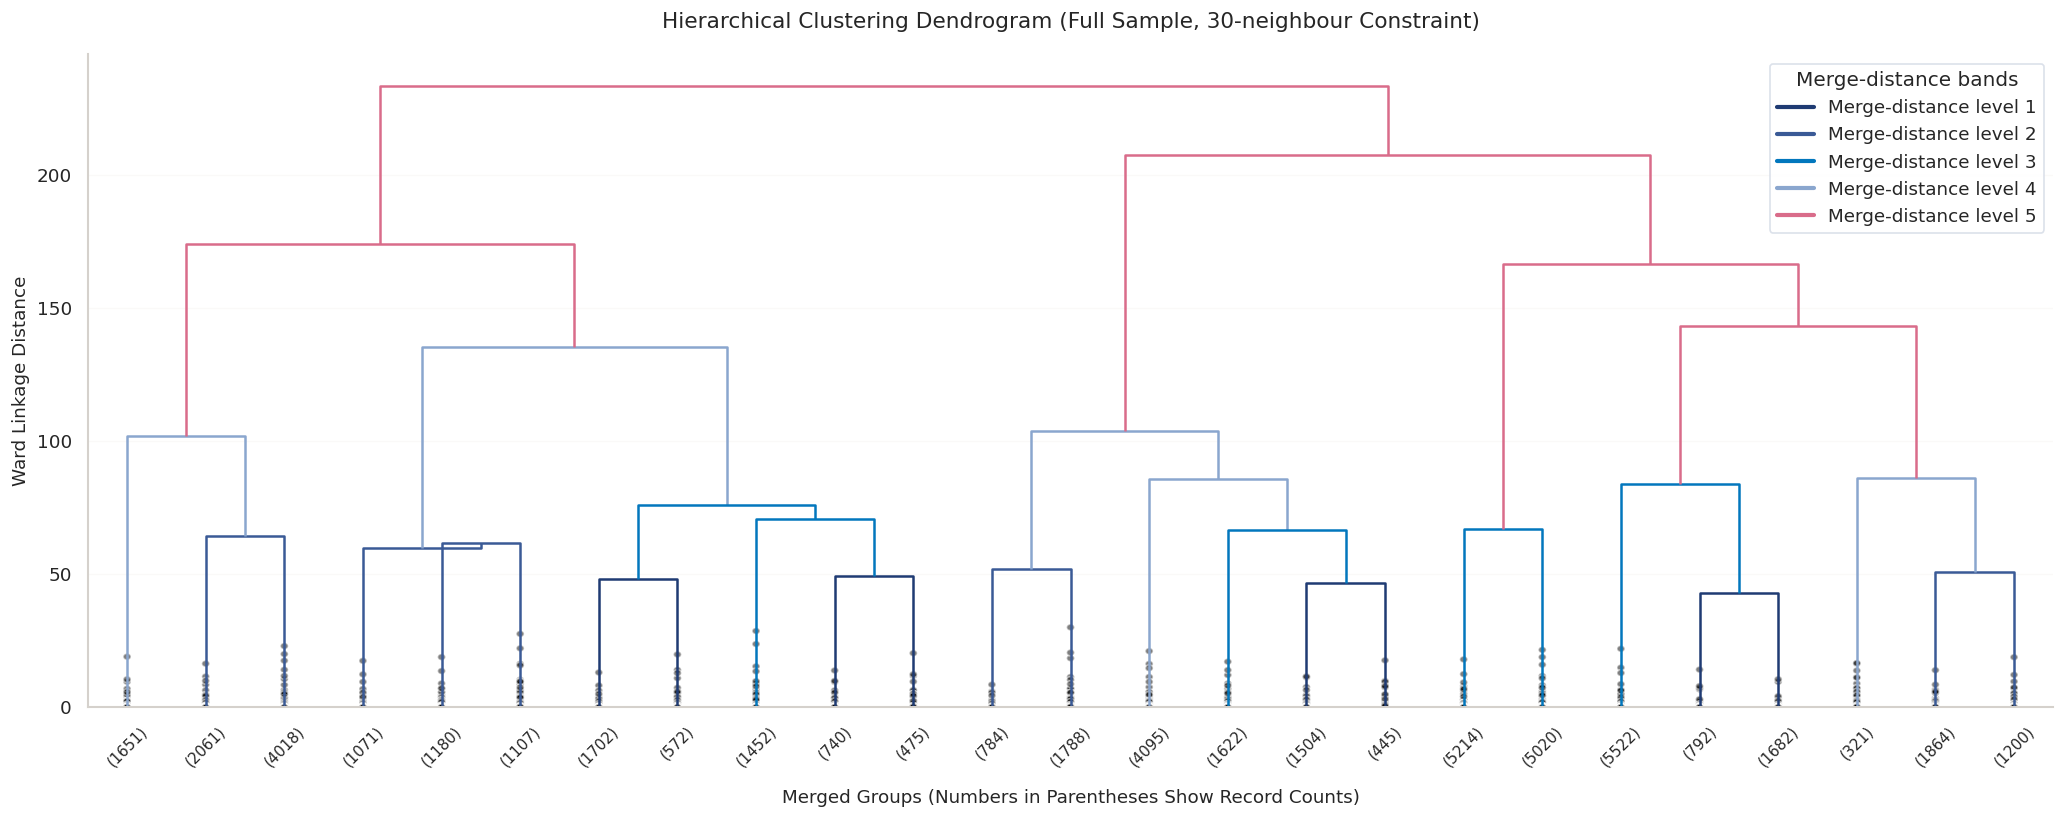

In [42]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import AgglomerativeClustering
from scipy.sparse import csr_matrix
from scipy.cluster.hierarchy import dendrogram
from matplotlib.lines import Line2D

# Load the cleaned analysis sample
q6_data_path = (
    Path.cwd() / "outputs" / "tables" / "HSBC_Q3_cleaned.xlsx"
)

q6_data = pd.read_excel(
    q6_data_path,
    sheet_name="Analysis Data",
    index_col="Source_Row"
)

q6_numeric_cols = ["INCOME", "TRB"]
q6_categorical_cols = ["DIG_ACTIVE", "PAYME", "FX_TRANS"]

# Apply log1p and sample-standard-deviation scaling
q6_log_values = np.log1p(
    q6_data[q6_numeric_cols].astype(float)
)

q6_numeric_scaled = (
    (q6_log_values - q6_log_values.mean())
    / q6_log_values.std(ddof=1)
)

# Calculate the same categorical weight used in Q5
q6_categorical_gini = [
    1 - (
        q6_data[col].value_counts(normalize=True) ** 2
    ).sum()
    for col in q6_categorical_cols
]

q6_gamma = (
    q6_numeric_scaled.var(ddof=1).mean()
    / np.mean(q6_categorical_gini)
)

q6_hier_X = np.column_stack([
    q6_numeric_scaled.to_numpy(dtype=float),
    q6_data[q6_categorical_cols].to_numpy(dtype=float)
    * np.sqrt(q6_gamma)
])

q6_n_records = len(q6_data)
q6_n_neighbors = int(
    globals().get("HIERARCHY_NEIGHBORS", 30)
)

print("Records:", q6_n_records)
print("Gamma:", q6_gamma)
print("Neighbours per record:", q6_n_neighbors)

# Build the symmetric nearest-neighbour graph
q6_neighbor_model = NearestNeighbors(
    n_neighbors=q6_n_neighbors,
    metric="euclidean",
    n_jobs=-1
).fit(q6_hier_X)

q6_neighbor_indices = q6_neighbor_model.kneighbors(
    return_distance=False
)

q6_connectivity = csr_matrix(
    (
        np.ones(q6_neighbor_indices.size, dtype=np.int8),
        (
            np.repeat(
                np.arange(q6_n_records),
                q6_n_neighbors
            ),
            q6_neighbor_indices.reshape(-1)
        )
    ),
    shape=(q6_n_records, q6_n_records)
)

q6_connectivity = q6_connectivity.maximum(
    q6_connectivity.T
)

# Fit the complete hierarchical tree
print("Fitting the hierarchical model...", flush=True)

q6_hier_model = AgglomerativeClustering(
    n_clusters=None,
    distance_threshold=0,
    linkage="ward",
    connectivity=q6_connectivity,
    compute_full_tree=True,
    compute_distances=True
).fit(q6_hier_X)

# Construct the linkage matrix
q6_hier_merge_counts = np.zeros(
    len(q6_hier_model.children_),
    dtype=int
)

for merge_index, children in enumerate(
    q6_hier_model.children_
):
    for child in children:
        if child < q6_n_records:
            q6_hier_merge_counts[merge_index] += 1
        else:
            q6_hier_merge_counts[merge_index] += (
                q6_hier_merge_counts[child - q6_n_records]
            )

q6_hier_linkage = np.column_stack([
    q6_hier_model.children_,
    q6_hier_model.distances_,
    q6_hier_merge_counts
]).astype(float)

print("Hierarchical model fitted.")
print("Linkage matrix shape:", q6_hier_linkage.shape)

# Define the dendrogram colours
q6_dendrogram_p = 25

q6_level_colors = [
    "#1F3B73",
    "#3A5A96",
    "#0277BD",
    "#8AA6CE",
    "#D96C8A"
]

q6_color_breaks = np.quantile(
    q6_hier_model.distances_[-q6_dendrogram_p:],
    [0.2, 0.4, 0.6, 0.8]
)

def q6_link_color_by_level(node_id):
    merge_height = q6_hier_model.distances_[
        int(node_id) - q6_n_records
    ]

    color_level = np.searchsorted(
        q6_color_breaks,
        merge_height,
        side="right"
    )

    return q6_level_colors[color_level]

# Plot the dendrogram
fig, ax = plt.subplots(figsize=(18, 8), facecolor="white")
ax.set_facecolor("white")

dendrogram(
    q6_hier_linkage,
    truncate_mode="lastp",
    p=q6_dendrogram_p,
    show_leaf_counts=True,
    show_contracted=True,
    leaf_rotation=45,
    leaf_font_size=9,
    link_color_func=q6_link_color_by_level,
    ax=ax
)

ax.set_title(
    "Hierarchical Clustering Dendrogram "
    f"(Full Sample, {q6_n_neighbors}-neighbour Constraint)",
    pad=16
)
ax.set_xlabel(
    "Merged Groups (Numbers in Parentheses Show Record Counts)",
    labelpad=12
)
ax.set_ylabel("Ward Linkage Distance")
ax.grid(axis="y", alpha=0.2)
ax.grid(axis="x", visible=False)

ax.legend(
    handles=[
        Line2D(
            [0], [0],
            color=color,
            lw=2.5,
            label=f"Merge-distance level {i + 1}"
        )
        for i, color in enumerate(q6_level_colors)
    ],
    title="Merge-distance bands",
    loc="upper right",
    frameon=True,
    facecolor="white",
    framealpha=0.9,
    edgecolor="#D8DEE8"
)

fig.subplots_adjust(
    left=0.07,
    right=0.98,
    bottom=0.22,
    top=0.90
)

q6_figure_dir = Path.cwd() / "outputs" / "figures"
q6_figure_dir.mkdir(parents=True, exist_ok=True)

for extension in ["png", "pdf"]:
    fig.savefig(
        q6_figure_dir
        / f"q6_hierarchical_dendrogram_colored.{extension}",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close(fig)

In [43]:
q6_merge_table = pd.DataFrame({
    "Merge_Number": np.arange(1, len(q6_hier_model.distances_) + 1),
    "Ward_Linkage_Distance": q6_hier_model.distances_,
    "Merged_Records": q6_hier_merge_counts.astype(int)
})

q6_merge_table["Clusters_After_Merge"] = (
    q6_n_records - q6_merge_table["Merge_Number"]
)

q6_recent_merges = q6_merge_table.tail(30).copy()
q6_recent_merges["Distance_Increase"] = (
    q6_recent_merges["Ward_Linkage_Distance"].diff()
)

display(q6_recent_merges.round(3))

,Merge_Number,Ward_Linkage_Distance,Merged_Records,Clusters_After_Merge,Distance_Increase
47851,47852,37.442,5020,30,NaN
47852,47853,37.721,4095,29,0.278
47853,47854,39.004,1107,28,1.284
47854,47855,40.473,5522,27,1.469
47855,47856,40.908,1788,26,0.435
47856,47857,42.929,4018,25,2.021
47857,47858,42.939,2474,24,0.010
47858,47859,46.720,1949,23,3.781
47859,47860,48.173,2274,22,1.453
47860,47861,49.357,1215,21,1.184


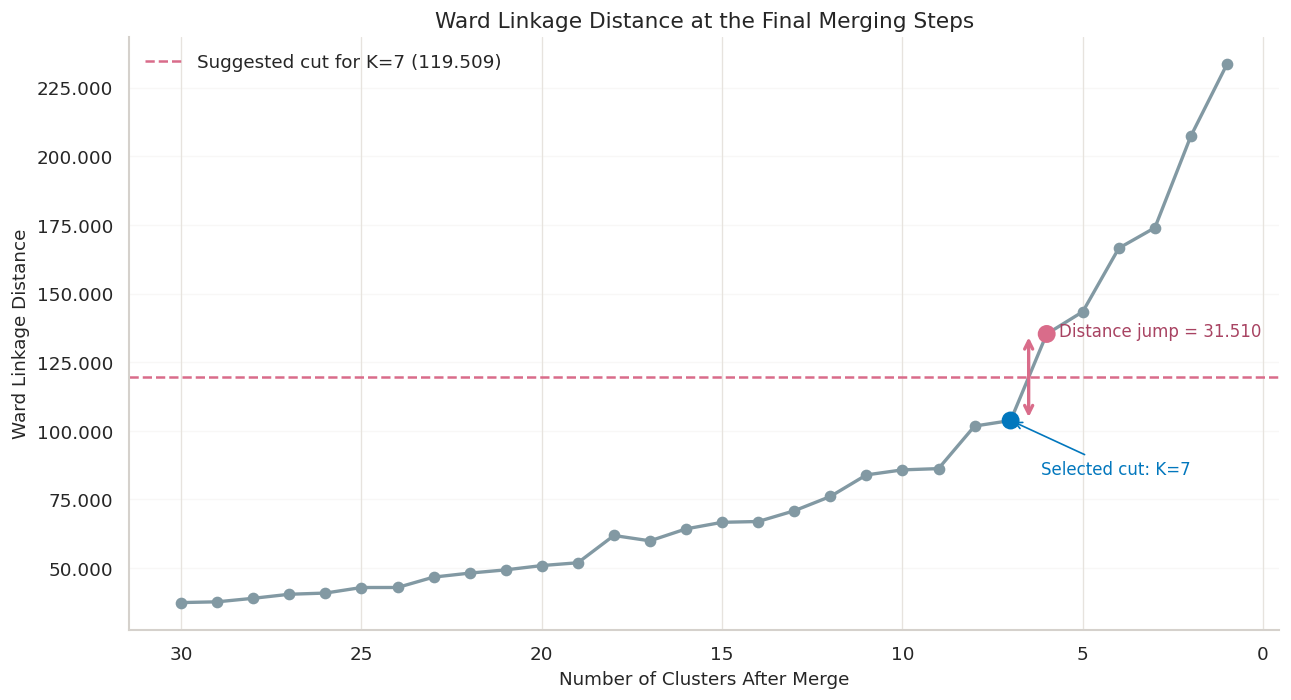

In [44]:
from matplotlib.lines import Line2D
from matplotlib.ticker import FormatStrFormatter

q6_jump_from_k7 = q6_merge_table.loc[
    q6_merge_table["Clusters_After_Merge"] == 7,
    "Ward_Linkage_Distance"
].iloc[0]

q6_jump_to_k6 = q6_merge_table.loc[
    q6_merge_table["Clusters_After_Merge"] == 6,
    "Ward_Linkage_Distance"
].iloc[0]

q6_jump_size = q6_jump_to_k6 - q6_jump_from_k7
q6_cut_height = (q6_jump_from_k7 + q6_jump_to_k6) / 2

q6_plot_merges = q6_recent_merges.sort_values(
    "Clusters_After_Merge",
    ascending=False
)

fig, ax = plt.subplots(figsize=(11, 6), facecolor="white")
ax.set_facecolor("white")

ax.plot(
    q6_plot_merges["Clusters_After_Merge"],
    q6_plot_merges["Ward_Linkage_Distance"],
    marker="o",
    color="#8299A3",
    linewidth=2
)

ax.scatter(
    [7, 6],
    [q6_jump_from_k7, q6_jump_to_k6],
    s=95,
    color=["#0277BD", "#D96C8A"],
    zorder=3
)

ax.axhline(
    q6_cut_height,
    color="#D96C8A",
    linestyle="--",
    linewidth=1.5,
    label=f"Suggested cut for K=7 ({q6_cut_height:.3f})"
)

ax.annotate(
    "",
    xy=(6.5, q6_jump_to_k6),
    xytext=(6.5, q6_jump_from_k7),
    arrowprops={
        "arrowstyle": "<->",
        "color": "#D96C8A",
        "linewidth": 2
    }
)

ax.annotate(
    f"Distance jump = {q6_jump_size:.3f}",
    xy=(6.5, q6_cut_height),
    xytext=(18, 22),
    textcoords="offset points",
    va="bottom",
    color="#A84362",
    fontsize=10
)

ax.annotate(
    "Selected cut: K=7",
    xy=(7, q6_jump_from_k7),
    xytext=(18, -32),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "#0277BD"},
    color="#0277BD",
    fontsize=10
)

ax.set_title("Ward Linkage Distance at the Final Merging Steps")
ax.set_xlabel("Number of Clusters After Merge")
ax.set_ylabel("Ward Linkage Distance")
ax.invert_xaxis()
ax.yaxis.set_major_formatter(FormatStrFormatter("%.3f"))
ax.grid(axis="y", alpha=0.25)

ax.legend(frameon=False, loc="upper left")

save_figure(fig, "q6_hierarchical_merge_distance_jump")

In [45]:
import numpy as np

from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import AgglomerativeClustering
from scipy.sparse import csr_matrix
from scipy.cluster.hierarchy import dendrogram

# Check the required Q0 and Q5 variables
required_variables = [
    "df_analysis",
    "q5_doc_numeric_scaled",
    "q5_doc_categorical_cols",
    "q5_doc_gamma",
    "HIERARCHY_NEIGHBORS"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the Q0 and Q5 preparation cells first. "
        f"Missing variables: {missing_variables}"
    )

# Prepare the weighted input using the existing Q5 settings
q6_hier_numeric = q5_doc_numeric_scaled.to_numpy(dtype=float)

q6_hier_categorical = (
    df_analysis[q5_doc_categorical_cols]
    .to_numpy(dtype=float)
)

q6_hier_X = np.column_stack([
    q6_hier_numeric,
    q6_hier_categorical * np.sqrt(q5_doc_gamma)
])

q6_n_records = len(q6_hier_X)
q6_n_neighbors = HIERARCHY_NEIGHBORS

# Build the nearest-neighbour connectivity graph
q6_neighbor_model = NearestNeighbors(
    n_neighbors=q6_n_neighbors,
    metric="euclidean",
    n_jobs=-1
)

q6_neighbor_model.fit(q6_hier_X)

q6_neighbor_indices = q6_neighbor_model.kneighbors(
    return_distance=False
)

q6_row_indices = np.repeat(
    np.arange(q6_n_records),
    q6_n_neighbors
)

q6_connectivity = csr_matrix(
    (
        np.ones(q6_neighbor_indices.size, dtype=np.int8),
        (
            q6_row_indices,
            q6_neighbor_indices.reshape(-1)
        )
    ),
    shape=(q6_n_records, q6_n_records)
)

q6_connectivity = q6_connectivity.maximum(
    q6_connectivity.T
)

print("Records:", q6_n_records)
print("Neighbours per record:", q6_n_neighbors)
print("Connectivity graph links:", q6_connectivity.nnz)
print("Fitting the hierarchical model...", flush=True)

# Fit the complete hierarchical tree
q6_hier_model = AgglomerativeClustering(
    n_clusters=None,
    distance_threshold=0,
    linkage="ward",
    connectivity=q6_connectivity,
    compute_full_tree=True,
    compute_distances=True
)

q6_hier_model.fit(q6_hier_X)

# Count the records in each merged node
q6_hier_merge_counts = np.zeros(
    len(q6_hier_model.children_),
    dtype=int
)

for merge_index, children in enumerate(
    q6_hier_model.children_
):
    for child in children:
        if child < q6_n_records:
            q6_hier_merge_counts[merge_index] += 1
        else:
            q6_hier_merge_counts[merge_index] += (
                q6_hier_merge_counts[child - q6_n_records]
            )

# Prepare the linkage matrix for the dendrogram
q6_hier_linkage = np.column_stack([
    q6_hier_model.children_,
    q6_hier_model.distances_,
    q6_hier_merge_counts
]).astype(float)

print("Hierarchical model fitted.")
print("Linkage matrix shape:", q6_hier_linkage.shape)

Records: 47882
Neighbours per record: 30
Connectivity graph links: 1677848
Fitting the hierarchical model...
Hierarchical model fitted.
Linkage matrix shape: (47881, 4)



### Profiles of the Seven Hierarchical Clusters

Cut the hierarchical tree into seven clusters and label them H1–H7 in ascending order of median monthly income. Summarize cluster sizes, financial characteristics, digital services, age composition, and product holdings. These labels do not imply correspondence with G1–G7 from Q5.

In [46]:
# Cut the tree by merge order, including internal tree nodes
def q6_cut_tree_by_merge_order(children, n_samples, n_clusters):
    if len(children) != n_samples - 1:
        raise ValueError("A complete hierarchical tree is required.")

    if not 1 <= n_clusters <= n_samples:
        raise ValueError("Invalid number of clusters.")

    parent = np.arange(n_samples)
    representatives = np.empty(2 * n_samples - 1, dtype=int)
    representatives[:n_samples] = np.arange(n_samples)

    def find_root(node):
        while parent[node] != node:
            parent[node] = parent[parent[node]]
            node = parent[node]
        return node

    for merge_index in range(n_samples - n_clusters):
        left, right = children[merge_index]

        left_root = find_root(representatives[left])
        right_root = find_root(representatives[right])

        parent[right_root] = left_root
        representatives[n_samples + merge_index] = left_root

    roots = np.array([
        find_root(i) for i in range(n_samples)
    ])

    return np.unique(roots, return_inverse=True)[1]


q6_hier7_labels = q6_cut_tree_by_merge_order(
    q6_hier_model.children_,
    n_samples=q6_n_records,
    n_clusters=7
)

# Use the same records and row order as the fitted model
q6_hier7_data = df_analysis.copy()

if len(q6_hier7_data) != q6_n_records:
    raise ValueError("The sample size differs from the fitted model.")

q6_hier7_data["RAW_CLUSTER"] = q6_hier7_labels

# Assign H1-H7 in ascending order of median income
q6_hier7_order = (
    q6_hier7_data.groupby("RAW_CLUSTER")["INCOME"]
    .median()
    .sort_values()
    .index
)

q6_hier7_mapping = {
    cluster: f"H{i + 1}"
    for i, cluster in enumerate(q6_hier7_order)
}

q6_hier7_data["CLUSTER"] = (
    q6_hier7_data["RAW_CLUSTER"].map(q6_hier7_mapping)
)

q6_hier7_grouped = q6_hier7_data.groupby("CLUSTER")

# Financial characteristics and cluster sizes
q6_hier7_main_profile = q6_hier7_grouped.agg(
    Customers=("INCOME", "size"),
    Mean_Income_HKD=("INCOME", "mean"),
    Median_Income_HKD=("INCOME", "median"),
    Mean_TRB_HKD=("TRB", "mean"),
    Median_TRB_HKD=("TRB", "median")
)

q6_hier7_main_profile.insert(
    1,
    "Share_Percent",
    q6_hier7_main_profile["Customers"]
    / len(q6_hier7_data) * 100
)

# Digital-service indicators
q6_hier7_digital_profile = (
    q6_hier7_grouped[["DIG_ACTIVE", "PAYME", "FX_TRANS"]]
    .mean()
    .mul(100)
    .rename(columns={
        "DIG_ACTIVE": "Digital_Banking_Rate_Percent",
        "PAYME": "PayMe_Rate_Percent",
        "FX_TRANS": "FX_Transaction_Rate_Percent"
    })
)

q6_hier7_main_profile = q6_hier7_main_profile.join(
    q6_hier7_digital_profile
)

# Age composition
q6_hier7_age_profile = (
    pd.crosstab(
        q6_hier7_data["CLUSTER"],
        q6_hier7_data["AGE"],
        normalize="index"
    )
    .reindex(columns=["18-24", "25-29", "30-34"], fill_value=0)
    .mul(100)
    .rename(columns=lambda age: f"AGE_{age}_Percent")
)

# Product holdings
q6_hier7_product_profile = (
    q6_hier7_grouped[
        ["CC", "LN", "MT", "TD", "SC", "SP", "BD", "MPF"]
    ]
    .mean()
    .mul(100)
    .rename(columns=lambda col: f"{col}_Percent")
)

q6_hier7_additional_profile = q6_hier7_age_profile.join(
    q6_hier7_product_profile
)

print("Number of clusters:", q6_hier7_data["CLUSTER"].nunique())
print("Total records:", q6_hier7_main_profile["Customers"].sum())

print("\nFinancial and digital-service profiles:")
display(q6_hier7_main_profile.round(3))

print("\nAge and product profiles:")
display(q6_hier7_additional_profile.round(3))

Number of clusters: 7
Total records: 47882

Financial and digital-service profiles:


,Customers,Share_Percent,Mean_Income_HKD,Median_Income_HKD,Mean_TRB_HKD,Median_TRB_HKD,Digital_Banking_Rate_Percent,PayMe_Rate_Percent,FX_Transaction_Rate_Percent
CLUSTER,,,,,,,,,
H1,3385,7.069,8106.100,7848.804,75438.701,42372.155,98.966,98.464,2.511
H2,4941,10.319,11314.359,9602.769,20510.019,2264.106,8.581,24.590,6.436
H3,7996,16.699,28659.006,22912.762,9313.168,5362.235,100.000,100.000,0.000
H4,7730,16.144,33843.804,27641.934,138180.850,25383.843,100.000,0.000,0.000
H5,3358,7.013,35453.541,28807.380,261134.427,113758.500,0.000,53.514,32.966
H6,10234,21.373,42252.502,35947.437,336894.180,186605.249,99.980,99.883,0.000
H7,10238,21.382,40063.074,36003.705,223479.779,83585.169,99.746,74.272,100.000



Age and product profiles:


,AGE_18-24_Percent,AGE_25-29_Percent,AGE_30-34_Percent,CC_Percent,LN_Percent,MT_Percent,TD_Percent,SC_Percent,SP_Percent,BD_Percent,MPF_Percent
CLUSTER,,,,,,,,,,,
H1,43.722,30.606,25.672,29.601,7.445,6.440,10.074,9.513,4.756,7.179,58.050
H2,30.642,30.480,38.879,15.786,5.444,4.695,6.153,6.375,4.716,5.120,12.993
H3,38.969,31.541,29.490,51.263,5.740,5.803,5.353,5.090,5.028,4.952,14.032
H4,31.125,30.517,38.357,39.625,6.766,7.167,8.836,8.357,4.942,6.300,22.380
H5,23.109,33.204,43.687,50.655,6.403,7.951,10.423,10.602,5.360,7.862,23.317
H6,17.031,35.333,47.635,70.657,10.768,11.989,11.667,13.260,5.071,9.635,42.007
H7,29.176,33.473,37.351,60.334,8.449,7.609,11.887,12.170,5.001,7.970,32.047


In [25]:
# Track the H1-H7 groups contained in each tree node
q6_node_groups = {
    i: frozenset([label])
    for i, label in enumerate(
        q6_hier7_data["CLUSTER"].to_numpy()
    )
}

q6_structure_rows = []

for merge_index, children in enumerate(
    q6_hier_model.children_
):
    left, right = map(int, children)

    left_groups = q6_node_groups.pop(left)
    right_groups = q6_node_groups.pop(right)

    q6_node_groups[q6_n_records + merge_index] = (
        left_groups | right_groups
    )

    # Report the six merges occurring after the seven-cluster cut
    if merge_index >= q6_n_records - 7:
        q6_structure_rows.append({
            "Left_Groups": " + ".join(sorted(left_groups)),
            "Right_Groups": " + ".join(sorted(right_groups)),
            "Ward_Linkage_Distance": (
                q6_hier_model.distances_[merge_index]
            ),
            "Merged_Records": int(
                q6_hier_merge_counts[merge_index]
            ),
            "Clusters_After_Merge": (
                q6_n_records - merge_index - 1
            )
        })

q6_hierarchy_structure = pd.DataFrame(q6_structure_rows)

display(q6_hierarchy_structure.round(3))

,Left_Groups,Right_Groups,Ward_Linkage_Distance,Merged_Records,Clusters_After_Merge
0,H5,H2,135.264,8299,6
1,H3,H1,143.372,11381,5
2,H6,H1 + H3,166.512,21615,4
3,H4,H2 + H5,173.964,16029,3
4,H7,H1 + H3 + H6,207.409,31853,2
5,H2 + H4 + H5,H1 + H3 + H6 + H7,233.542,47882,1


##### 1. Profiles of the Seven Clusters

The hierarchical tree was cut into seven clusters, labelled H1–H7 in ascending order of median monthly income. Together, they contain 47,882 records, with cluster shares ranging from 7.01% to 21.38%. These labels do not imply correspondence with G1–G7 from Q5.

| Cluster | Customers | Median income (HKD) | Median TRB (HKD) | Main interpretation |
|---|---:|---:|---:|---|
| H1 | 3,385 | 7,848.80 | 42,372.15 | Lower income with high digital banking and PayMe coverage. Younger customers are relatively common, but the group cannot automatically be classified as students. |
| H2 | 4,941 | 9,602.77 | 2,264.11 | Lower income, low bank balances, and low digital-service coverage. Service onboarding and channel support may be relevant areas to investigate. |
| H3 | 7,996 | 22,912.76 | 5,362.24 | Digital banking and PayMe indicators are both 100%, with no FX transaction indicator, but balances at the bank remain relatively low. |
| H4 | 7,730 | 27,641.93 | 25,383.84 | Digital banking coverage is 100%, while PayMe and FX indicators are both 0%. Payment-service onboarding may be worth investigating. |
| H5 | 3,358 | 28,807.38 | 113,758.50 | Relatively strong financial characteristics despite a 0% digital banking indicator. The data do not establish the reasons for this pattern. |
| H6 | 10,234 | 35,947.44 | 186,605.25 | Higher income and balances, near-universal digital banking and PayMe coverage, and no FX indicator. Credit-card ownership is the highest among the seven groups at 70.66%. |
| H7 | 10,238 | 36,003.71 | 83,585.17 | All customers have an FX transaction indicator, digital banking coverage is 99.75%, and PayMe coverage is 74.27%. |

The profiles show that financial characteristics and digital-service coverage represent different dimensions. H2 and H5 both have low digital banking coverage, but H5 has substantially higher income and TRB. Similarly, H3 and H6 have comparable digital-service patterns but very different balances at the bank.

##### 2. Hierarchy and Structure

The six merges following the seven-cluster cut are:

| Left groups | Right groups | Ward linkage distance | Merged records | Remaining clusters |
|---|---|---:|---:|---:|
| H5 | H2 | 135.264 | 8,299 | 6 |
| H3 | H1 | 143.372 | 11,381 | 5 |
| H6 | H1 + H3 | 166.512 | 21,615 | 4 |
| H4 | H2 + H5 | 173.964 | 16,029 | 3 |
| H7 | H1 + H3 + H6 | 207.409 | 31,853 | 2 |
| H2 + H4 + H5 | H1 + H3 + H6 + H7 | 233.542 | 47,882 | 1 |

H5 and H2 merge first. Both have low digital banking coverage, although their financial profiles differ. H3 and H1 then merge, sharing high digital banking and PayMe coverage and low FX transaction rates.

H6 subsequently joins H1 and H3, forming a 21,615-record branch with broadly similar digital-service patterns but internal financial differences. H4 joins H2 and H5, producing a 16,029-record branch with more mixed digital-service characteristics.

At the three-cluster level, the tree consists of H1+H3+H6, H2+H4+H5, and H7. H7 remains separate until a relatively high linkage distance of 207.409, consistent with its distinctive FX transaction profile. These interpretations combine the observed merge structure with the profiles; they do not establish that any single variable caused a merge.

##### 3. Choice of Seven Clusters

The linkage distance rises from 103.754 when seven clusters remain to 135.264 when they merge into six, an increase of 31.510. Stopping before this jump preserves the seven groups.

Larger jumps also occur at higher levels, supporting a coarser three-group interpretation. Seven clusters were retained to preserve more useful financial and digital-service distinctions. This is a supported analytical choice rather than a uniquely optimal cut.

##### 4. Comparison with K-means and Q5 K-prototypes

Ward hierarchical clustering builds a nested tree through successive, irreversible merges. K-means specifies K in advance and repeatedly updates memberships and numerical means, producing a flat partition rather than a merge hierarchy.

K-prototypes also specifies K in advance but combines numerical means with categorical modes. Its objective differs from Ward clustering, so selecting seven clusters in both methods does not imply identical memberships.

For example, hierarchical H7 includes FX customers with different PayMe states, whereas Q5’s G6 and G7 distinguish these PayMe states. The hierarchical solution also identifies H5, a financially stronger group with a 0% digital banking indicator. Membership agreement would require a cross-tabulation or a separate agreement measure.

Finally, the hierarchical tree uses a 30-nearest-neighbour connectivity constraint, which affects the permitted merges. The profiles describe group-level patterns and do not establish individual occupations, total wealth, channel preferences, or marketing responses. Service-registration indicators should not be interpreted as direct measures of recent activity.